#  Trabajo Final Machine Learning
## Ejercicio 1: Regresión - Resistencia a compresión del hormigón
**Grupo:** A
**Integrantes:** Matías Diaz - Melina Yamgotchlan - Noelía García - Federico Otte

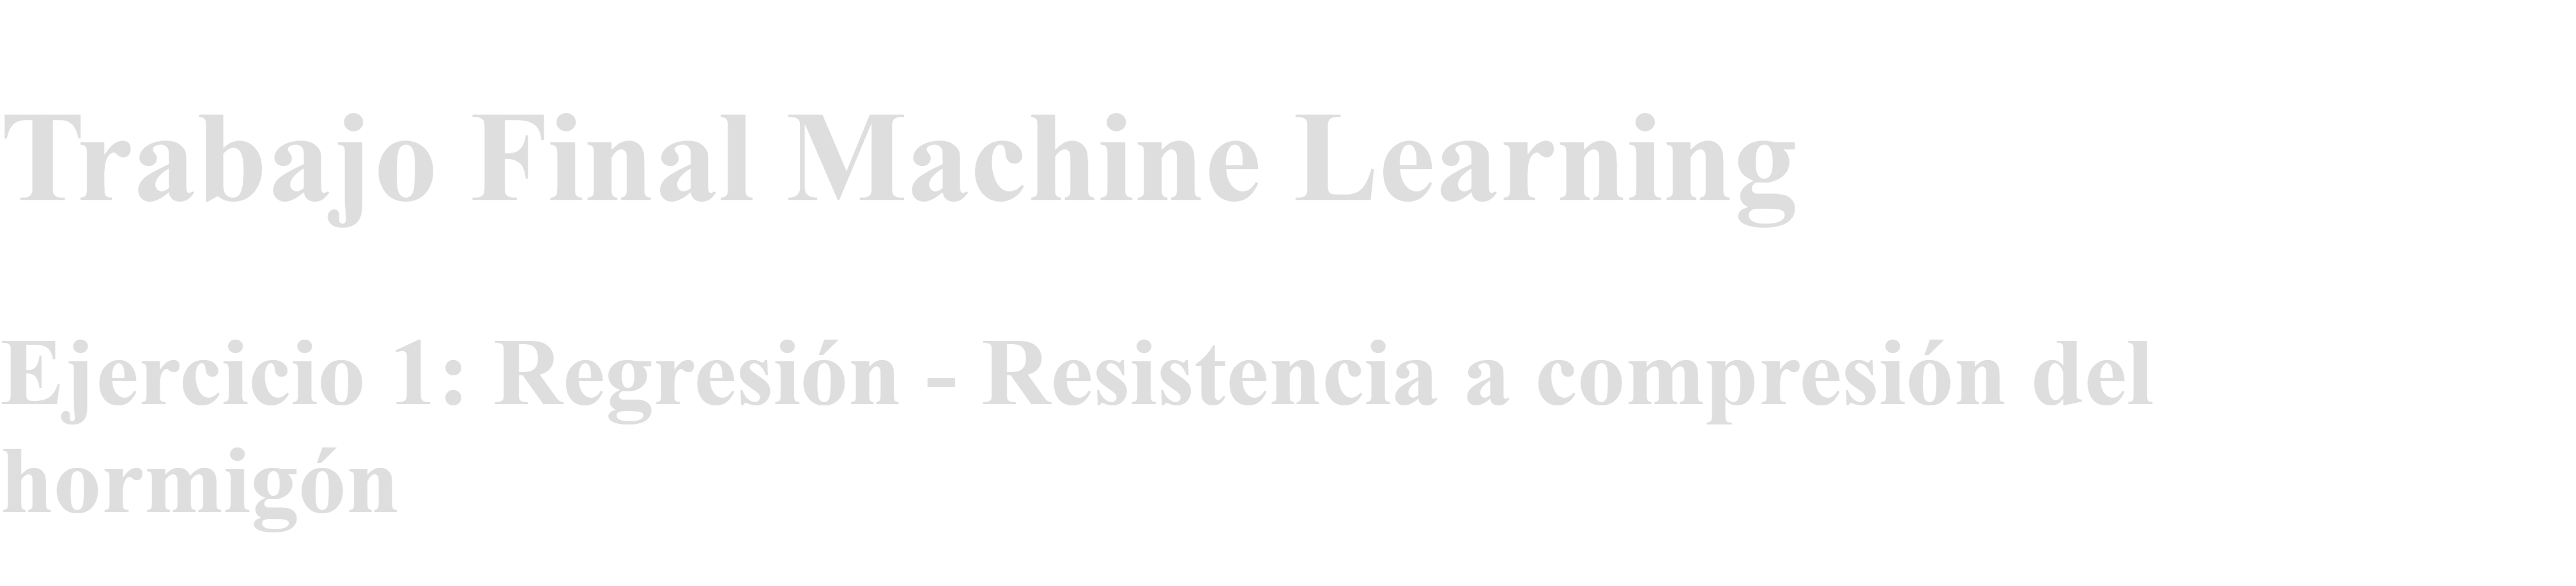

## Índice

1. Metadata
2. Análisis exploratorio de datos (EDA)
3. División en entrenamiento y prueba
4. Modelos y validación cruzada
5. Resultados
6. Importancia de variables
7. Interpretación final
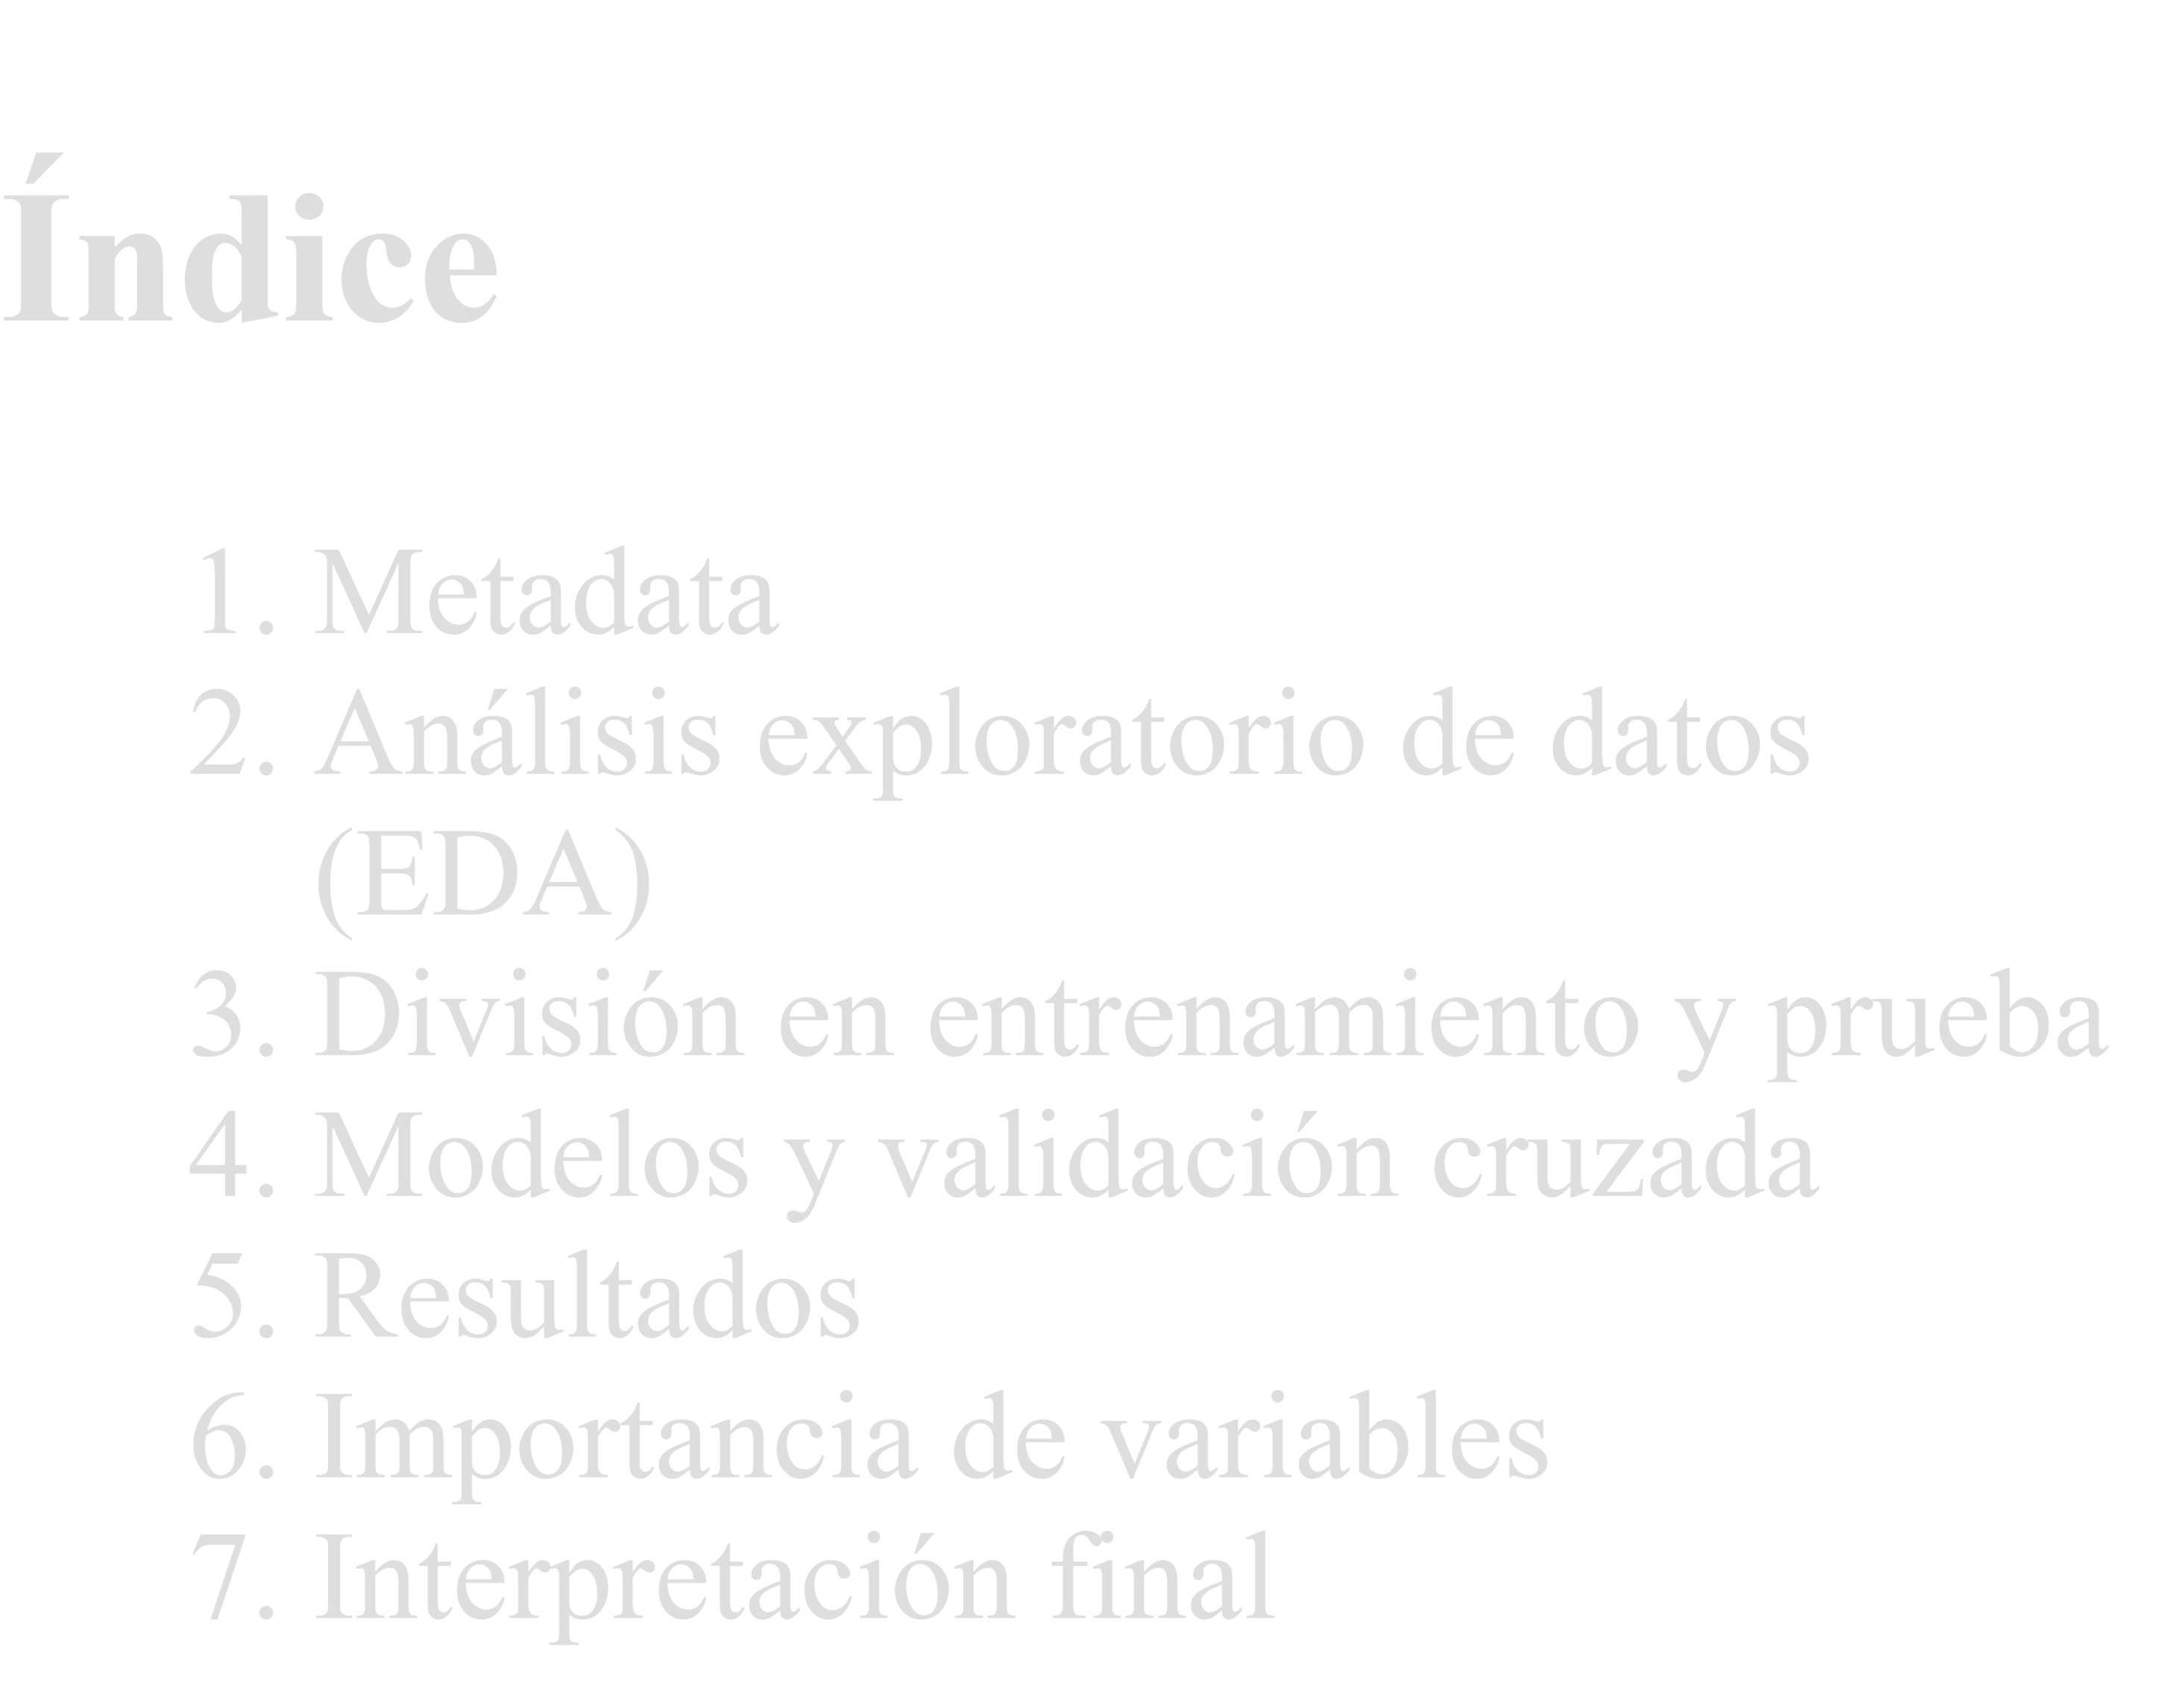

## 1. Metadata

| Campo | Descripción |
|---|---|
| Fuente | UCI Machine Learning Repository, Concrete Compressive Strength (id 165) |
| Tipo de problema | Regresión (aprendizaje supervisado) |
| Variable objetivo | Resistencia a compresión del hormigón (MPa) |
| Variables predictoras | 7 ingredientes de la mezcla (kg/m³): cemento, escoria, ceniza, agua, superplastificante, agregado grueso y agregado fino. Además, la edad del ensayo (días) |
| Cantidad de filas | 1030 (1005 después de eliminar duplicados) |
| Valores nulos | No hay |
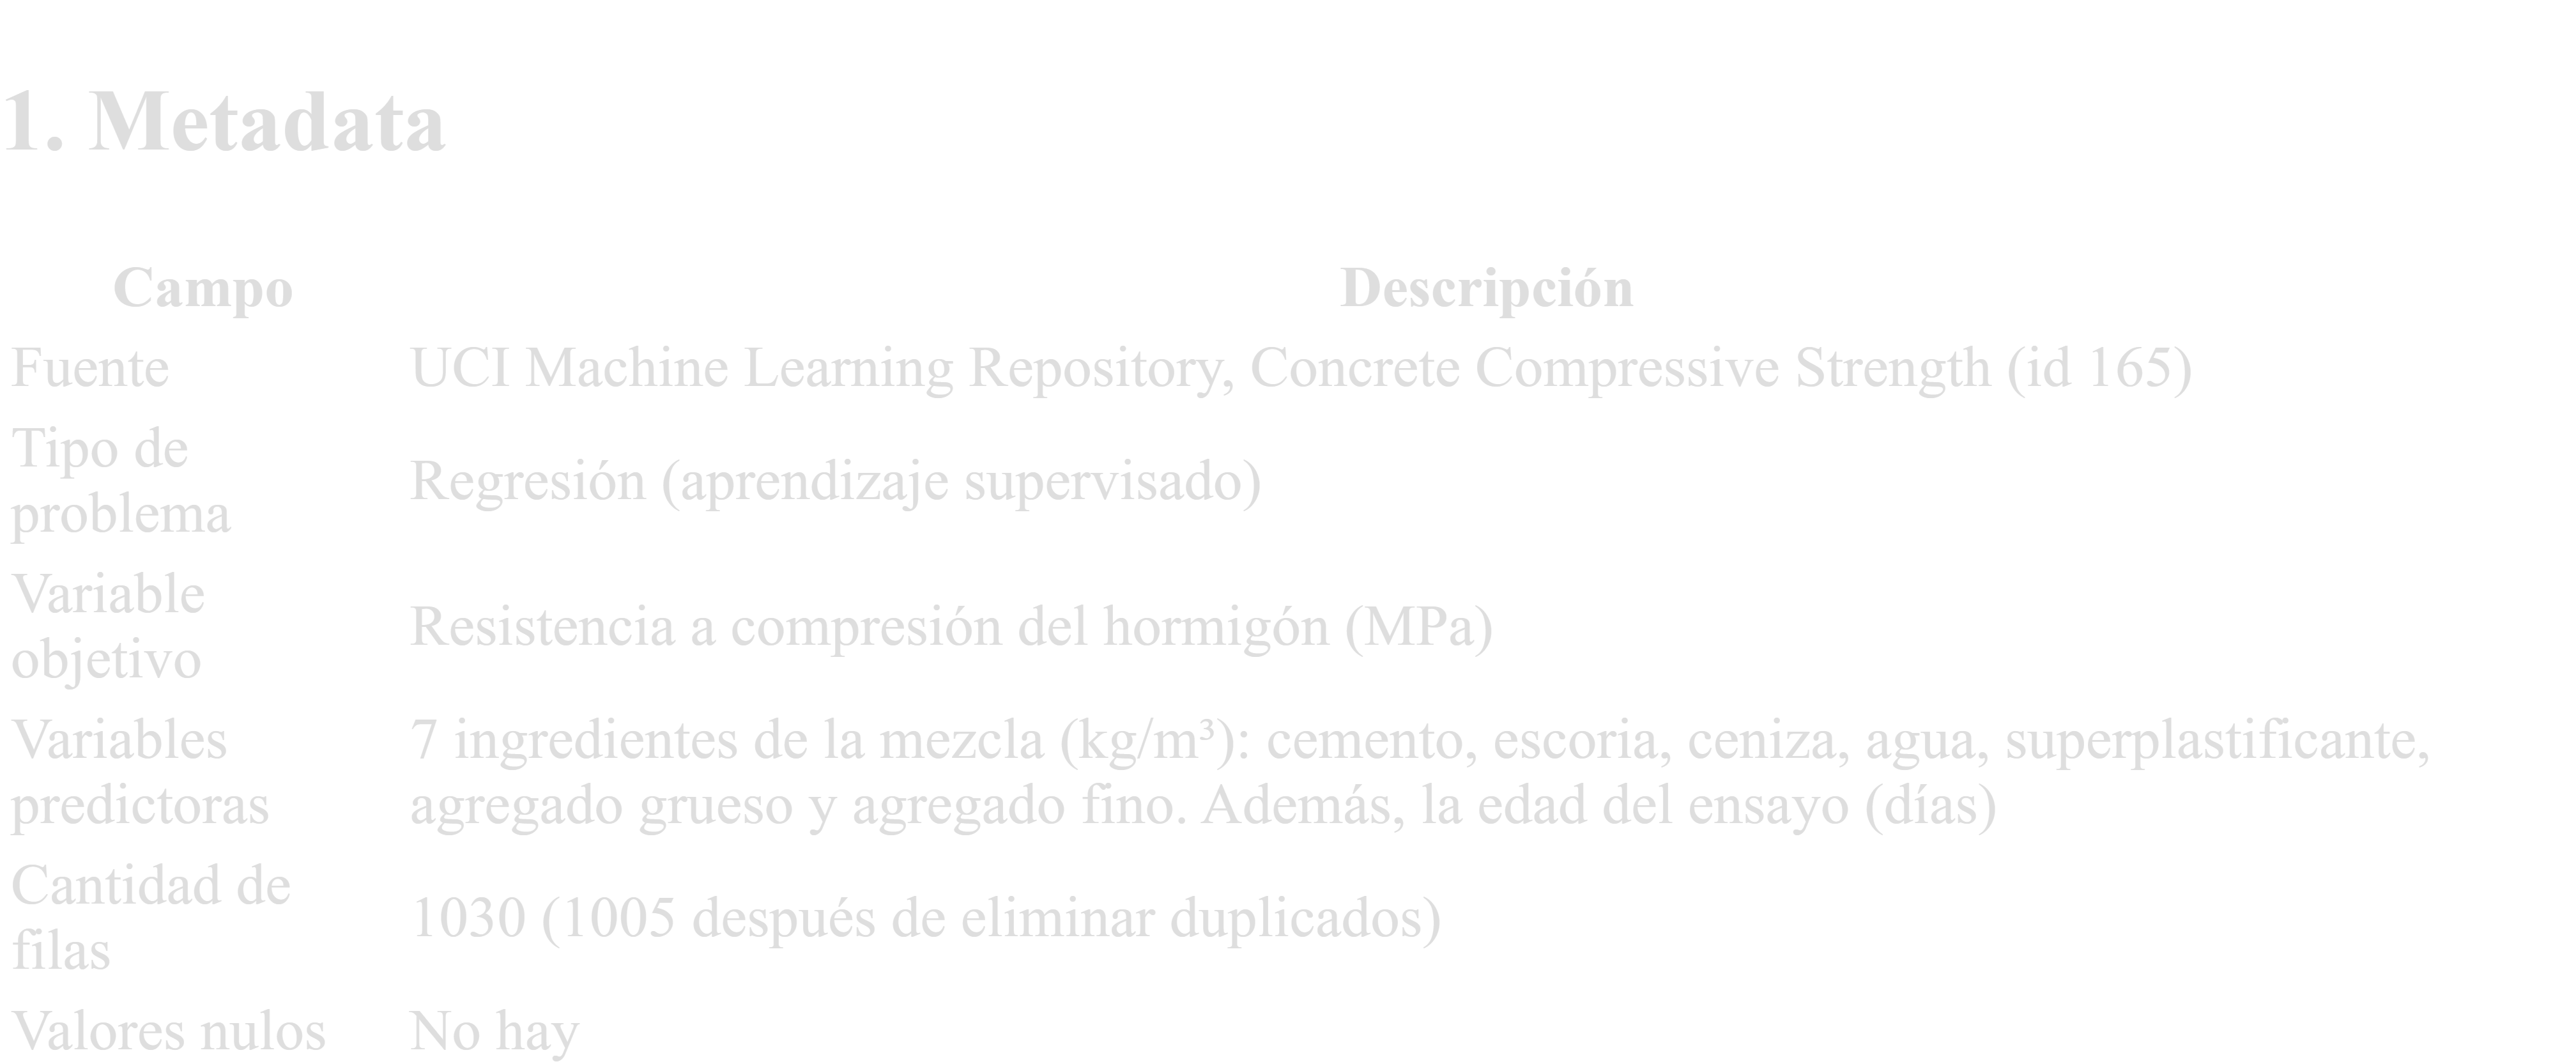

## 2. Análisis exploratorio de datos (EDA)

Antes de entrenar modelos se revisan los datos: rangos, faltantes, duplicados
y relación de cada variable con la resistencia.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [2]:
concrete = fetch_ucirepo(id=165)

X = concrete.data.features   # variables predictoras
y = concrete.data.targets    # variable objetivo

print("Predictoras:", X.columns.tolist())
print("Objetivo:", y.columns.tolist())

Predictoras: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']
Objetivo: ['Concrete compressive strength']


In [3]:
df = pd.concat([X, y], axis=1)

df.columns = [
    "cemento", "escoria", "ceniza", "agua", "superplastificante",
    "agregado_grueso", "agregado_fino", "edad", "resistencia"
]

df.head()

,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


Se unen predictoras y objetivo en una tabla y se renombran las columnas al español.

In [4]:
print("Dimensiones (filas, columnas):", df.shape)
df.info()

Dimensiones (filas, columnas): (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cemento             1030 non-null   float64
 1   escoria             1030 non-null   float64
 2   ceniza              1030 non-null   float64
 3   agua                1030 non-null   float64
 4   superplastificante  1030 non-null   float64
 5   agregado_grueso     1030 non-null   float64
 6   agregado_fino       1030 non-null   float64
 7   edad                1030 non-null   int64  
 8   resistencia         1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


El dataset tiene 1030 filas y 9 columnas. No hay valores faltantes y todas las
columnas son numéricas.

In [5]:
display(df.describe().T.round(2))
print("Duplicados:", df.duplicated().sum())
print(df["edad"].value_counts().sort_index())

,count,mean,std,min,25%,50%,75%,max
cemento,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
escoria,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
ceniza,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
agua,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
superplastificante,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
agregado_grueso,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
agregado_fino,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
edad,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
resistencia,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


Duplicados: 25
edad
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64


### Estadísticas descriptivas

**Observaciones:**
- La resistencia va de 2,3 a 82,6 MPa (promedio 35,8 MPa).
- Escoria, ceniza y superplastificante tienen mínimo 0: no todas las mezclas los usan.
- La mayoría de los ensayos son a 28 días (425 Registros). Hay pocos a edades largas.
- Hay 25 filas duplicadas.

### Eliminación de duplicados

Las 25 filas duplicadas son ensayos idénticos: misma mezcla, misma edad y
misma resistencia. Se eliminan porque, si se dejan, el modelo les daría más
peso que al resto de los datos.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print("Nuevas dimensiones:", df.shape)

Nuevas dimensiones: (1005, 9)


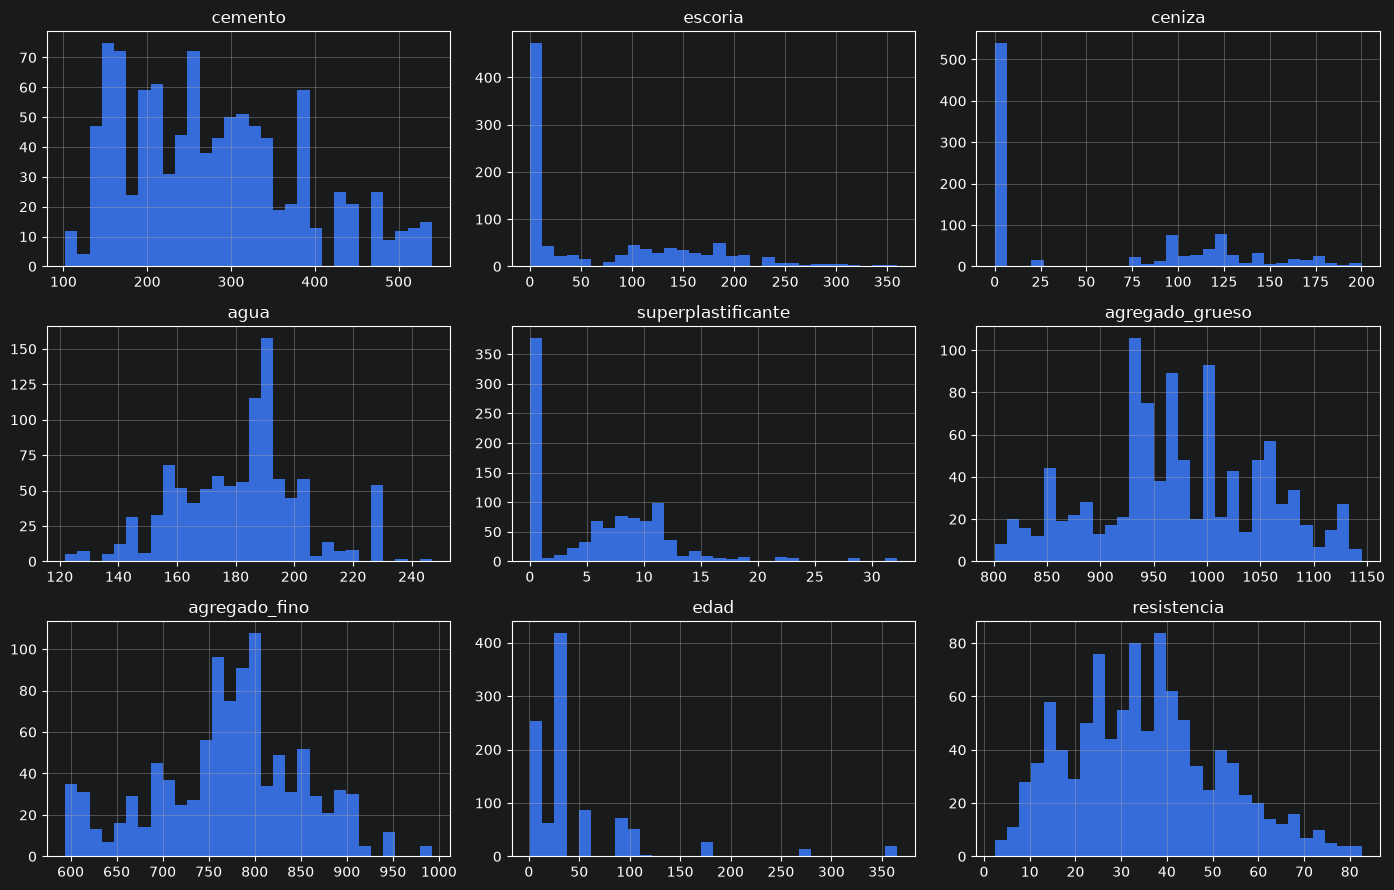

In [7]:
df.hist(bins=30, figsize=(14, 9))
plt.tight_layout()
plt.show()

### Distribución de las variables

**Observaciones:**
- Escoria, ceniza y superplastificante tienen muchos valores en cero.
- La edad se concentra en valores bajos.
- La resistencia tiene forma parecida a una campana.

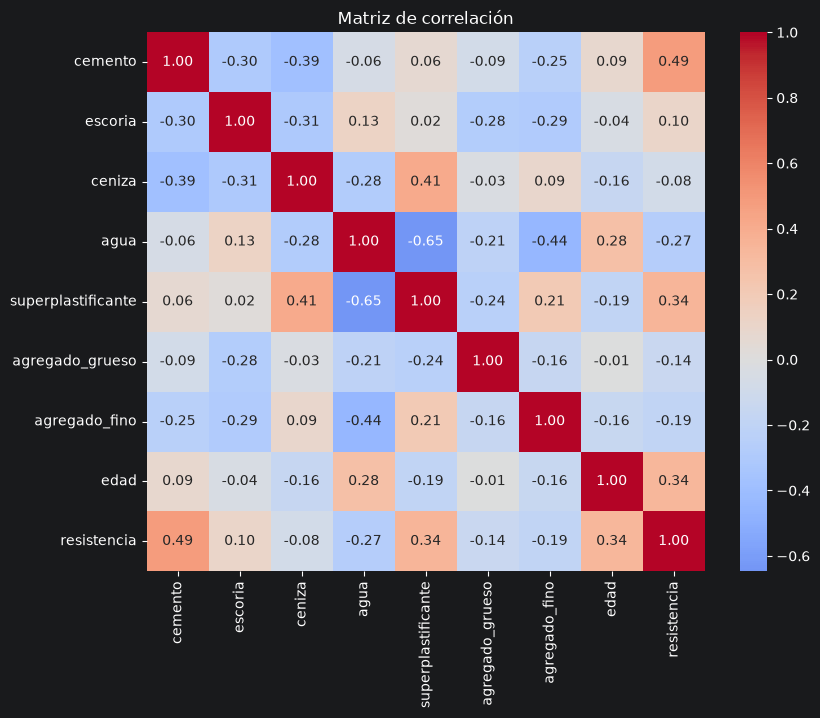

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

### Matriz de correlación

Mide si dos variables suben o bajan juntas en línea recta. Va de -1 a +1;
cerca de 0 significa que no hay relación lineal.

**Observaciones:**
- Cemento es la variable más relacionada con la resistencia (relación positiva).
- El agua tiene relación negativa: más agua, menos resistencia.
- Ninguna correlación es muy alta: la resistencia depende de varias variables a la vez.

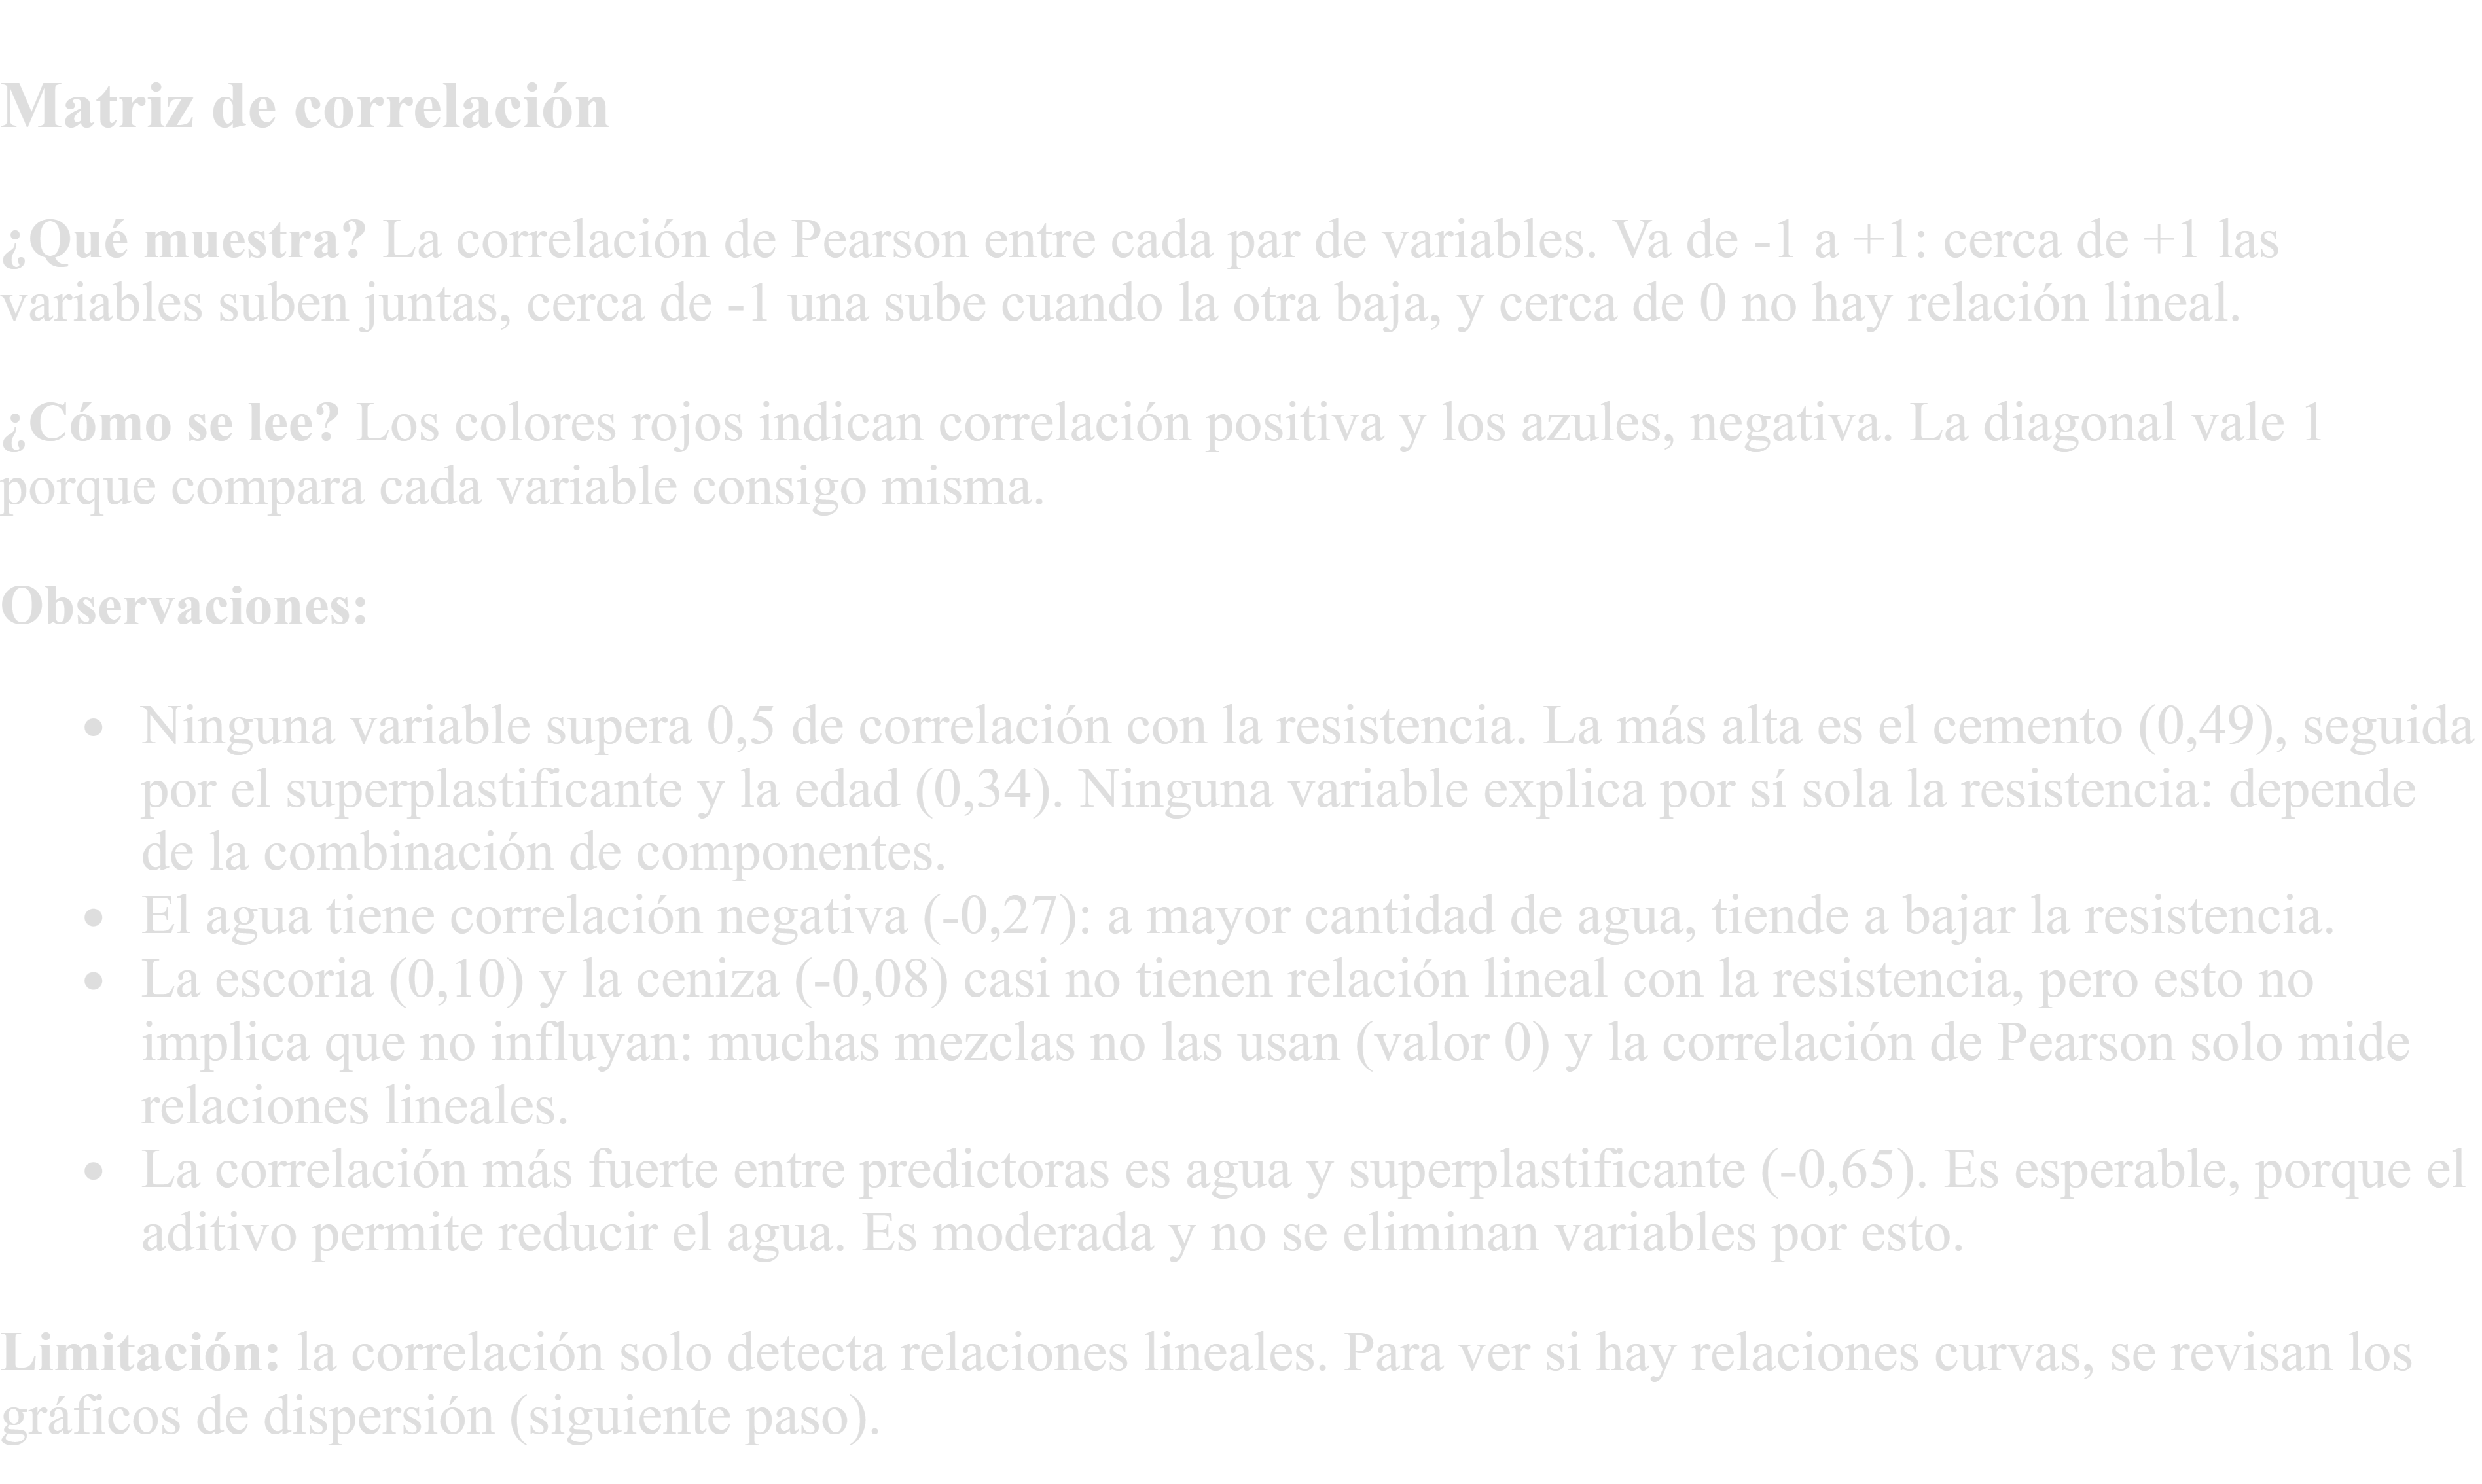

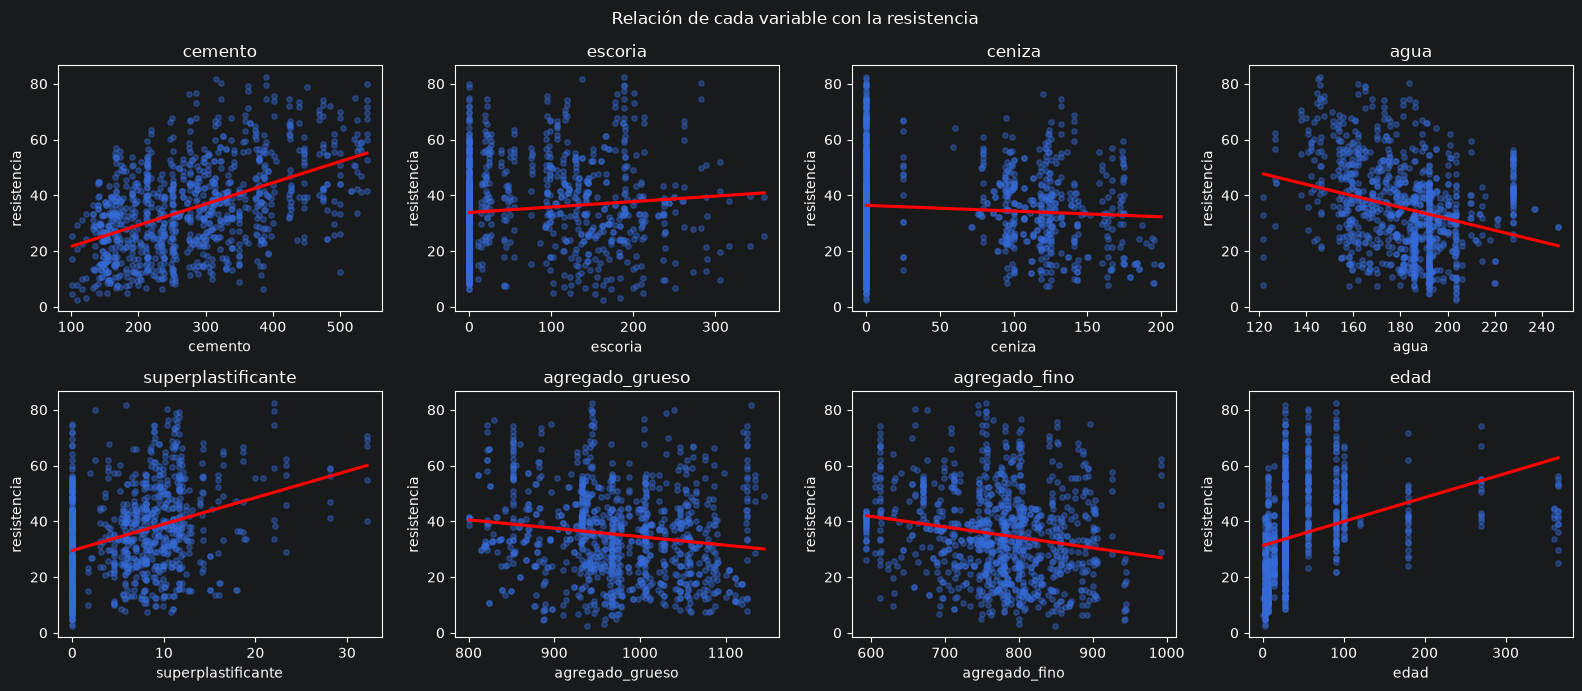

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, col in zip(axes.ravel(), df.columns[:-1]):
    sns.regplot(data=df, x=col, y="resistencia", ax=ax, ci=None,
                scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    ax.set_title(col)

fig.suptitle("Relación de cada variable con la resistencia")
plt.tight_layout()
plt.show()

### Relación de cada variable con la resistencia

**Observaciones:**
- Cemento, superplastificante y edad suben con la resistencia; el agua baja.
- Los puntos están muy dispersos: ninguna variable sola explica la resistencia.
- La edad no sigue una línea recta: la resistencia sube rápido al principio y
  después se estabiliza.

**Conclusión:** como hay relaciones curvas, además de la regresión lineal se
prueban modelos basados en árboles.
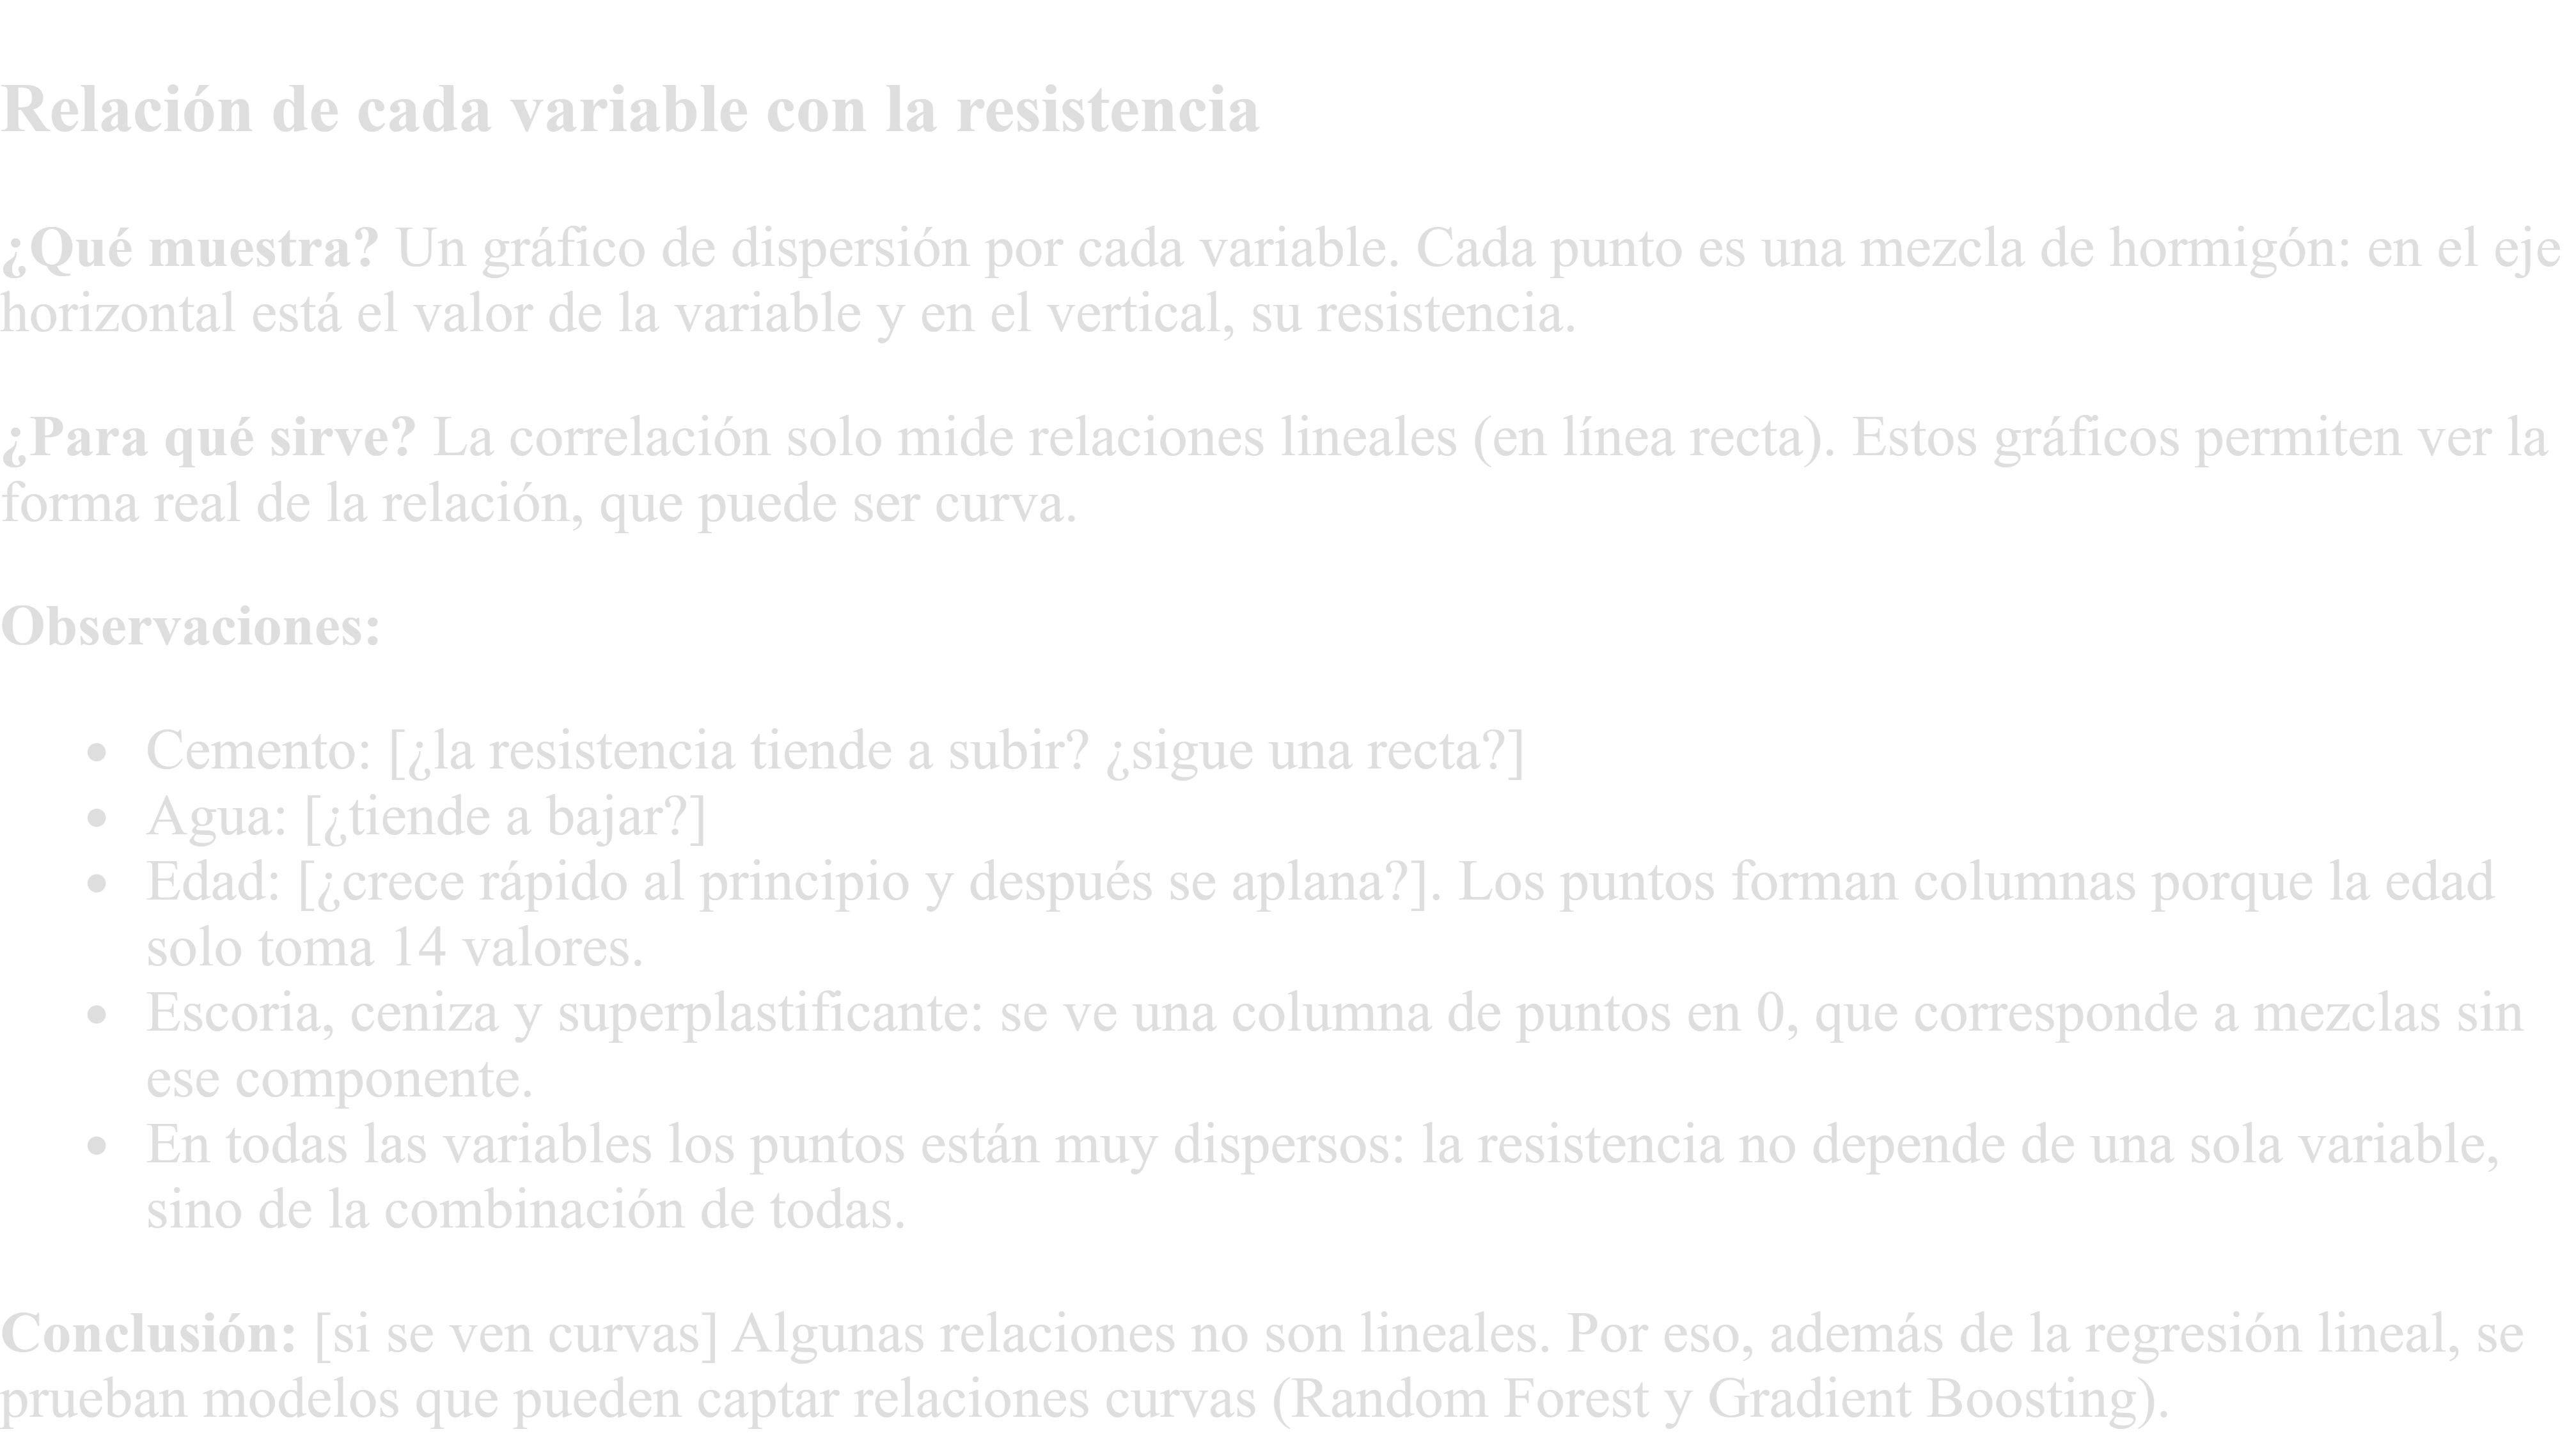

In [10]:
receta = df.drop(columns=["edad", "resistencia"])

print("Filas:", len(df))
print("Recetas distintas:", len(receta.drop_duplicates()))

Filas: 1005
Recetas distintas: 427


### Recetas repetidas (GROUP-BASED SPLIT)

Hay 1005 filas pero solo 427 recetas distintas: la misma receta se ensayó a
varias edades. Si se dividen las filas al azar, el modelo podría evaluarse con
una receta que ya vio.
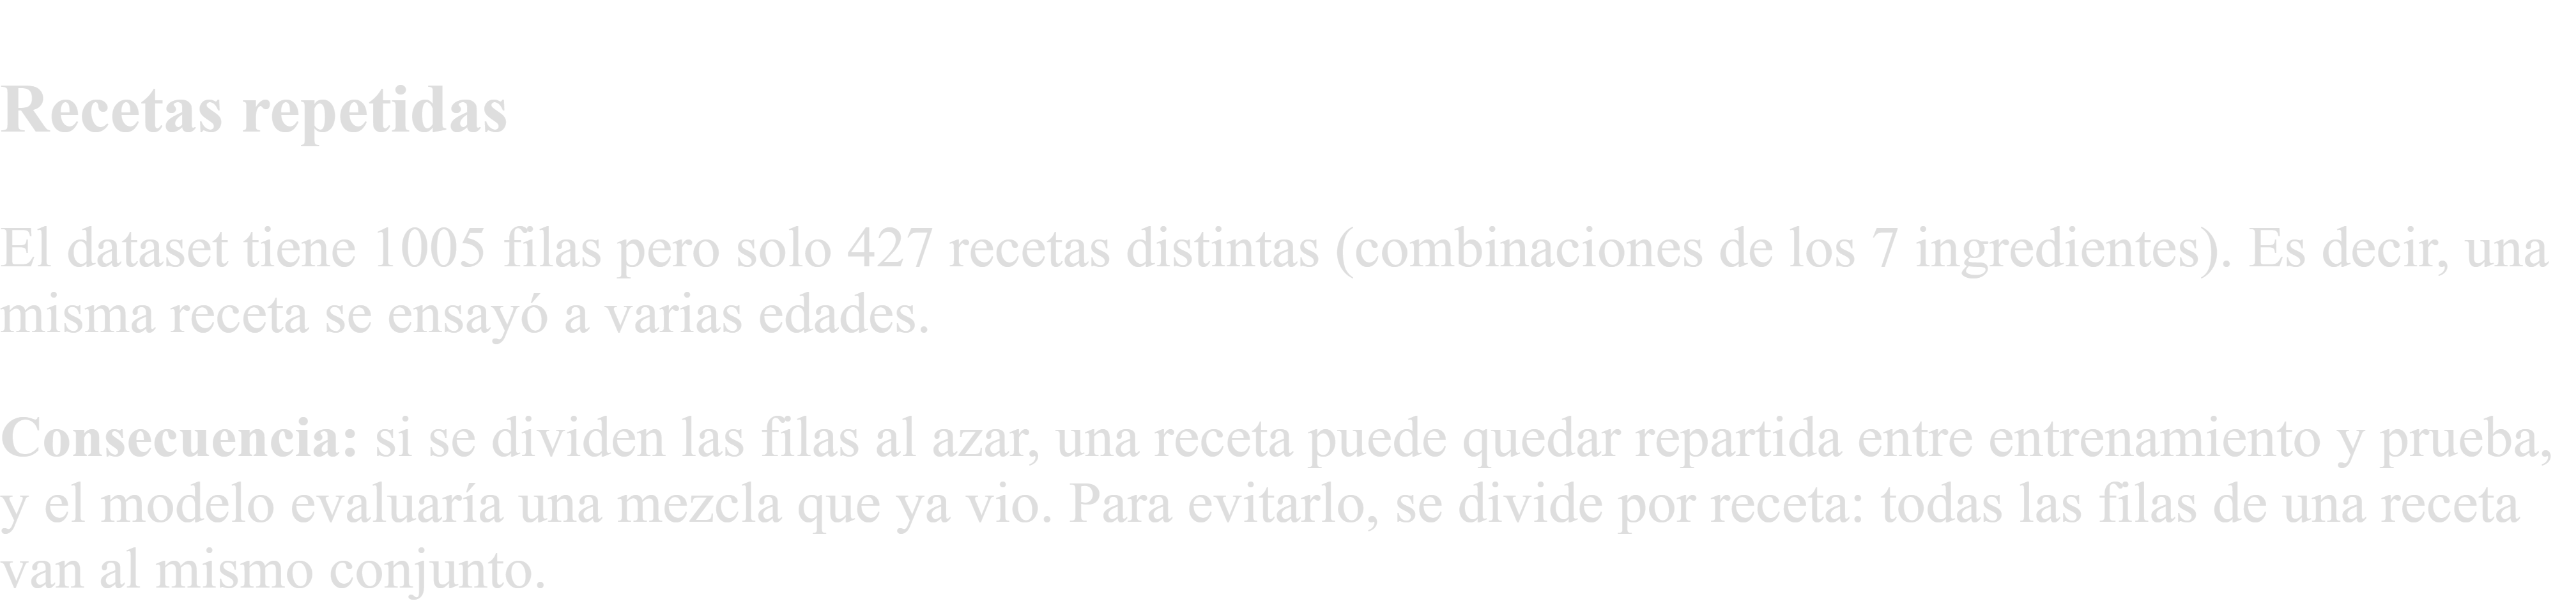

## 3. División en entrenamiento y prueba

Se separan los datos en dos bloques:
- **Entrenamiento (80 %):** el modelo aprende con estos datos.
- **Prueba (20 %):** se guardan aparte y solo se usan al final, para medir
  qué tan bien predice datos que nunca vio.

Así se puede detectar el **sobreajuste**: cuando el modelo memoriza los datos
de entrenamiento en lugar de aprender la relación general.

Como se vio en el punto anterior, la división se hace **por receta** con
`GroupShuffleSplit`: se asigna un número a cada receta y se reparten recetas
completas entre entrenamiento y prueba, no filas sueltas.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

X = df.drop(columns="resistencia")
y = df["resistencia"]

# Un número de grupo por cada receta (misma combinación de ingredientes)
ingredientes = ["cemento", "escoria", "ceniza", "agua",
                "superplastificante", "agregado_grueso", "agregado_fino"]
grupos = df.groupby(ingredientes).ngroup()

# División 80/20 sin separar las filas de una misma receta
division = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(division.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
compartidas = set(grupos.iloc[idx_train]) & set(grupos.iloc[idx_test])
print("Recetas en ambos conjuntos:", len(compartidas))

Entrenamiento: (813, 8)  Prueba: (192, 8)
Recetas en ambos conjuntos: 0


In [12]:
print(X_test["edad"].value_counts().sort_index())

edad
1       1
3      24
7      18
14     13
28     85
56     19
90      6
91      3
100    12
120     1
180     4
270     2
365     4
Name: count, dtype: int64


### Resultado de la división

- Entrenamiento: 813 filas. Prueba: 192 filas.
- Ninguna receta aparece en los dos conjuntos.

**Limitación:** en prueba hay pocos ensayos de edades largas.
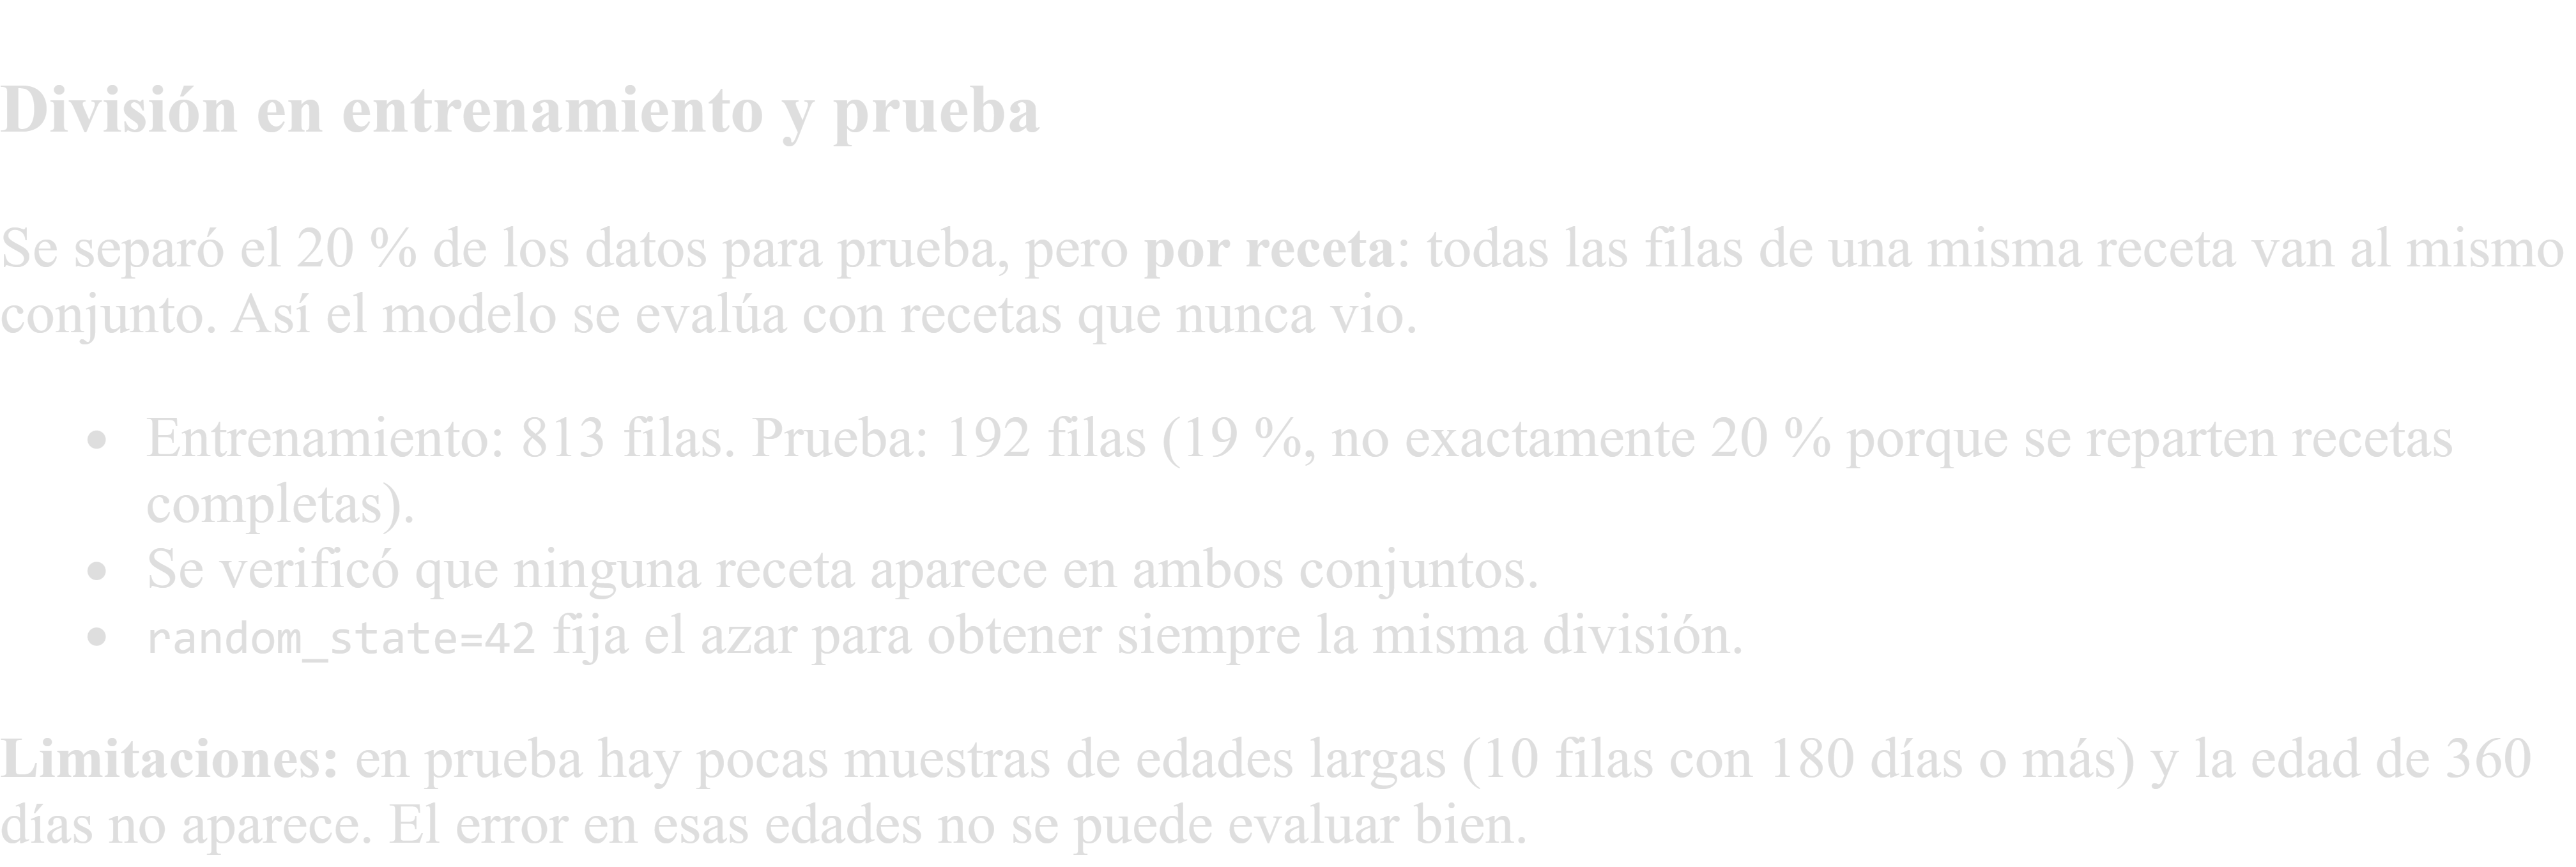

## 4. Modelos y validación cruzada

- **Regresión lineal:** busca la recta que mejor se ajusta a los datos. Solo
  capta relaciones en línea recta.
- **Random Forest:** entrena muchos árboles de decisión y promedia sus
  predicciones. Capta relaciones curvas y es estable.
- **Gradient Boosting:** entrena árboles uno tras otro; cada uno corrige los
  errores del anterior.


**Validación cruzada (5 folds):** el entrenamiento se divide en 5 partes; se
entrena con 4 y se evalúa con la restante, 5 veces. Da un resultado más
confiable que una sola evaluación. Con `GroupKFold` se respeta la división
por receta.

In [13]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

modelos = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

cv = GroupKFold(n_splits=5)
filas = []

for nombre, modelo in modelos.items():
    # 1) Validación cruzada solo con entrenamiento, agrupando por receta
    r2_cv = cross_val_score(modelo, X_train, y_train, cv=cv,
                            groups=grupos_train, scoring="r2")

    # 2) Entrenar con todo el entrenamiento y evaluar en prueba
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)

    filas.append({
        "Modelo": nombre,
        "R2 CV": r2_cv.mean(),
        "R2 test": r2_score(y_test, pred),
        "RMSE test": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE test": mean_absolute_error(y_test, pred),
    })

tabla = pd.DataFrame(filas).round(3)
tabla

,Modelo,R2 CV,R2 test,RMSE test,MAE test
0,Regresión lineal,0.579,0.590,9.916,7.698
1,Random Forest,0.856,0.854,5.920,4.494
2,Gradient Boosting,0.860,0.826,6.461,4.730


## 5. Resultados

**Métricas:**
- **MAE:** error promedio en MPa.
- **RMSE:** error en MPa que castiga más los errores grandes.
- **R²:** qué parte de la variación de la resistencia explica el modelo (de 0 a 1).

| Modelo | R² CV | R² test | RMSE test (MPa) | MAE test (MPa) |
|---|---|---|---|---|
| Regresión lineal | 0,58 | 0,59 | 9,92 | 7,70 |
| Random Forest | 0,86 | 0,85 | 5,92 | 4,49 |
| Gradient Boosting | 0,86 | 0,83 | 6,46 | 4,73 |

**Observaciones:**
- Los modelos de árboles superan claramente a la regresión lineal.
- Random Forest es el mejor en prueba: se equivoca en promedio 4,5 MPa.
- No hay sobreajuste: R² de validación cruzada y de prueba son parecidos.
- Predecir siempre el promedio daría un error de 16,7 MPa. Random Forest lo
  baja a 5,9 MPa.
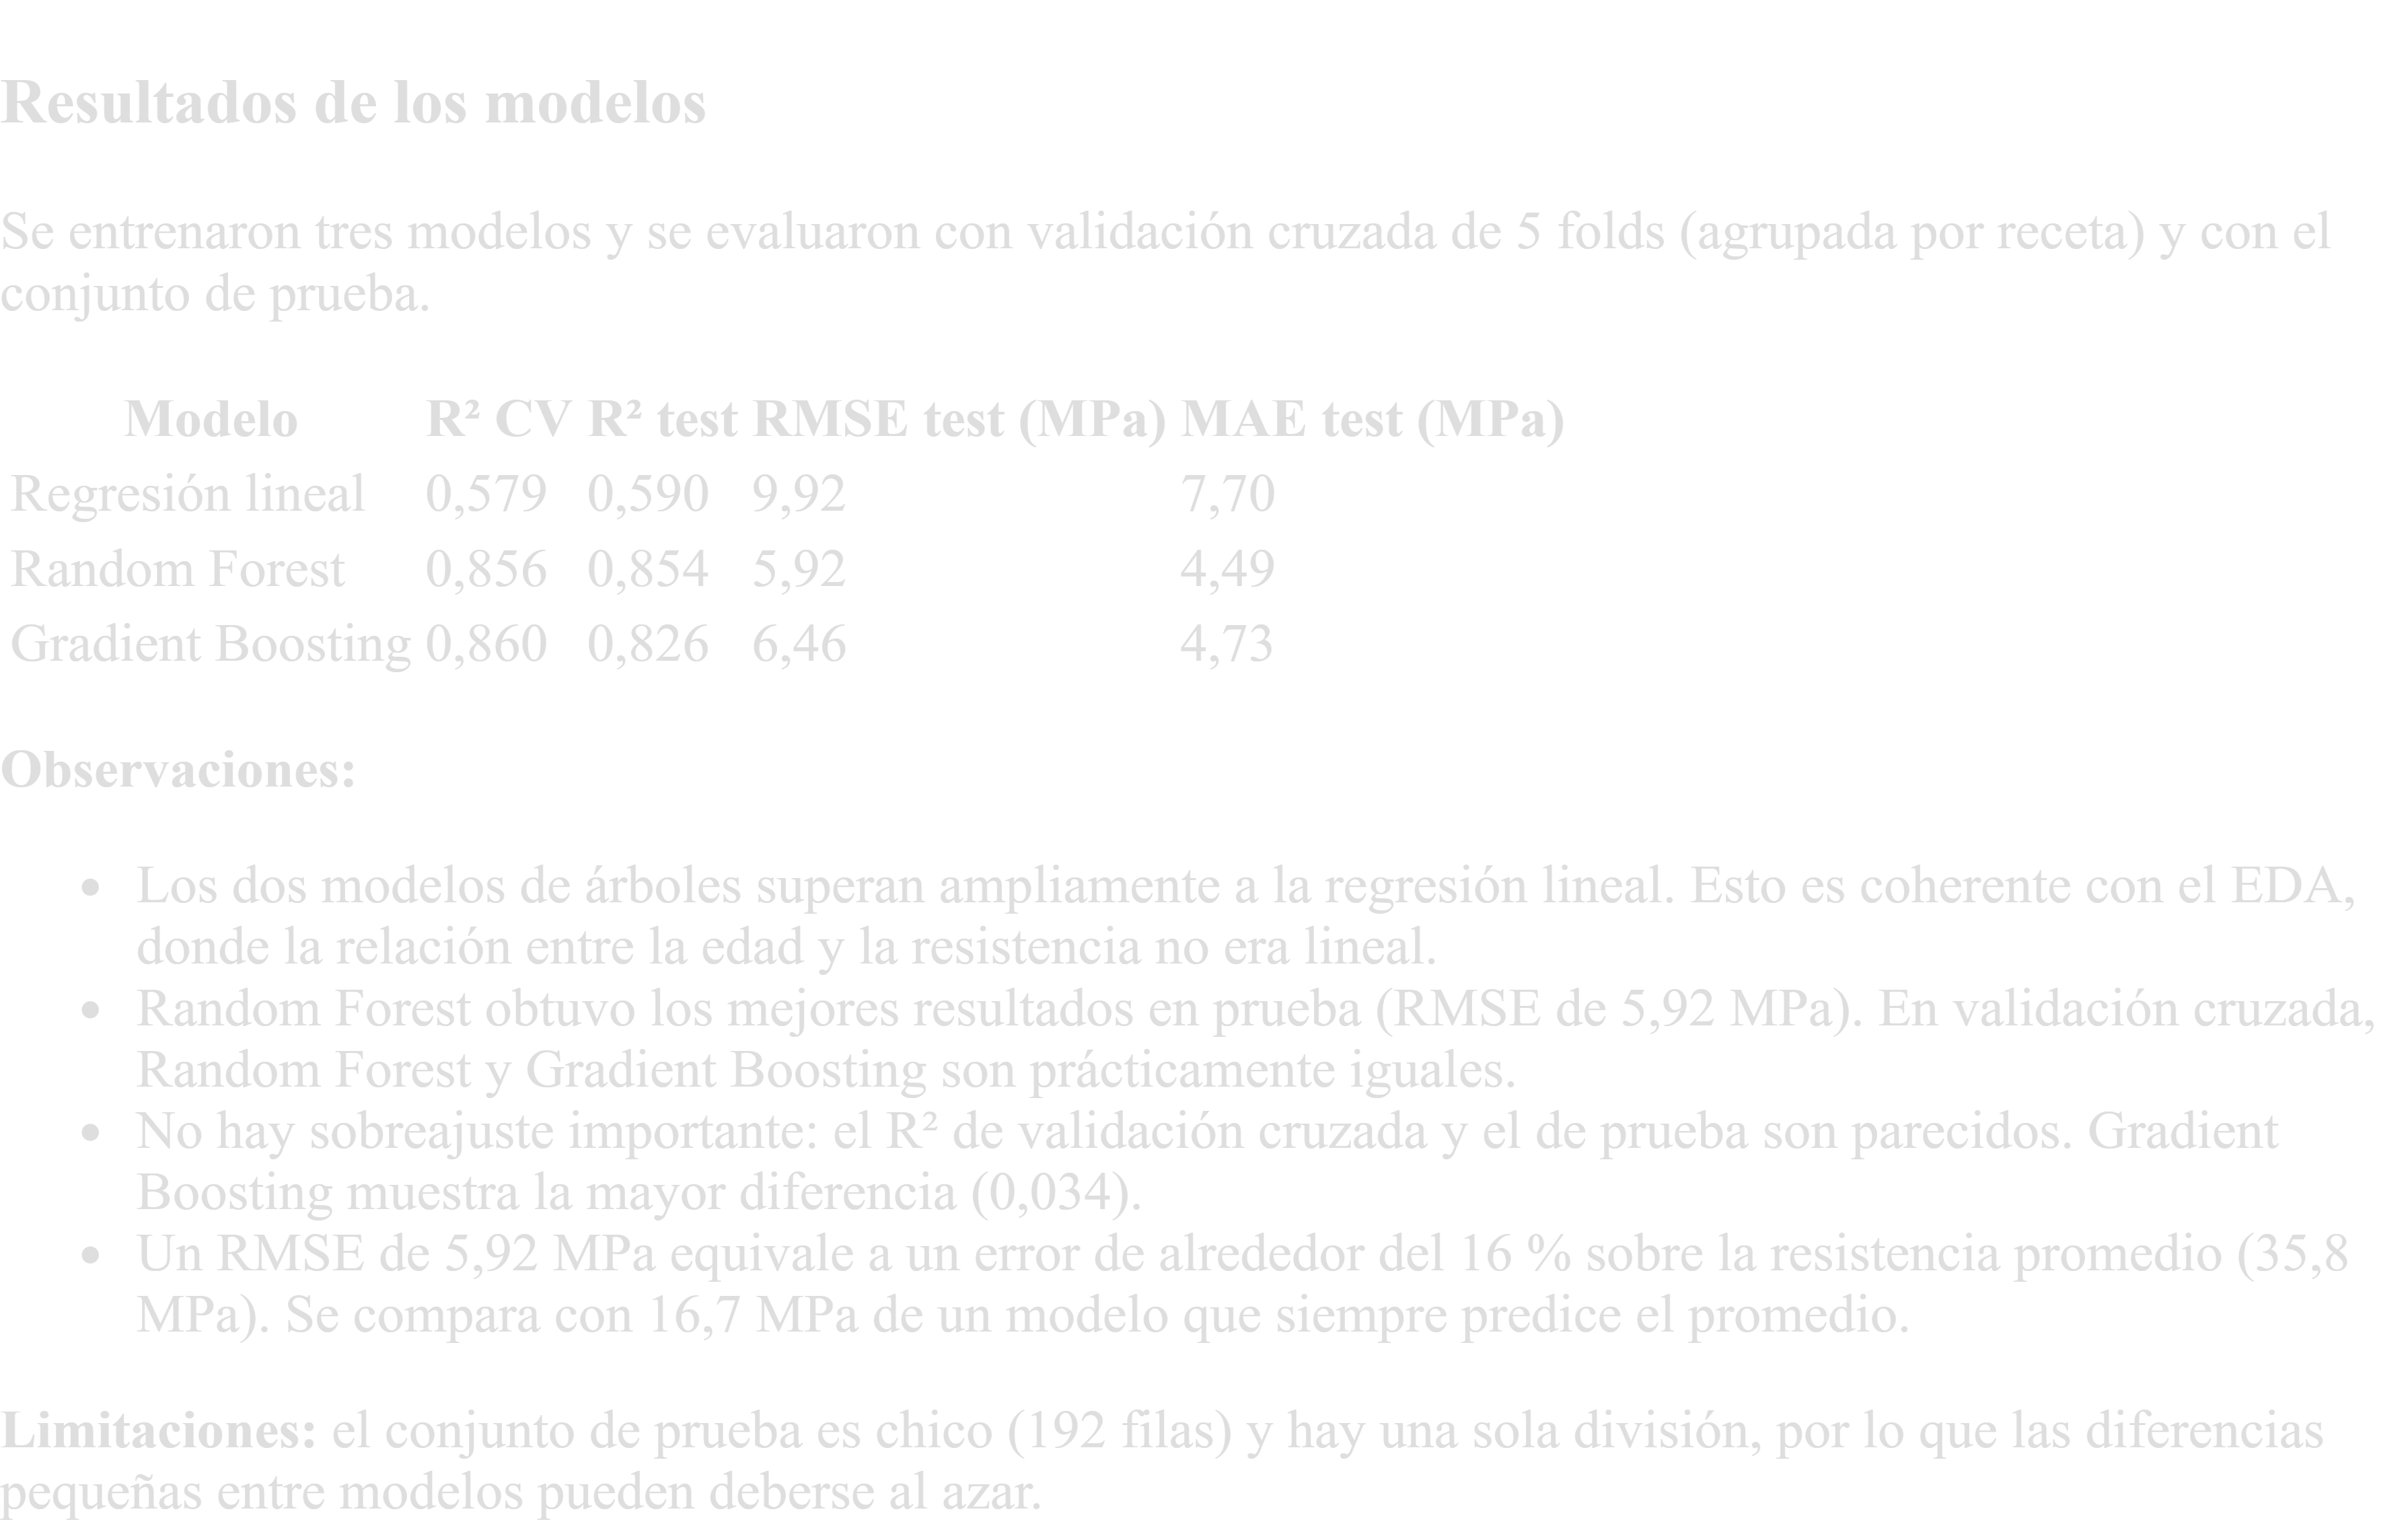

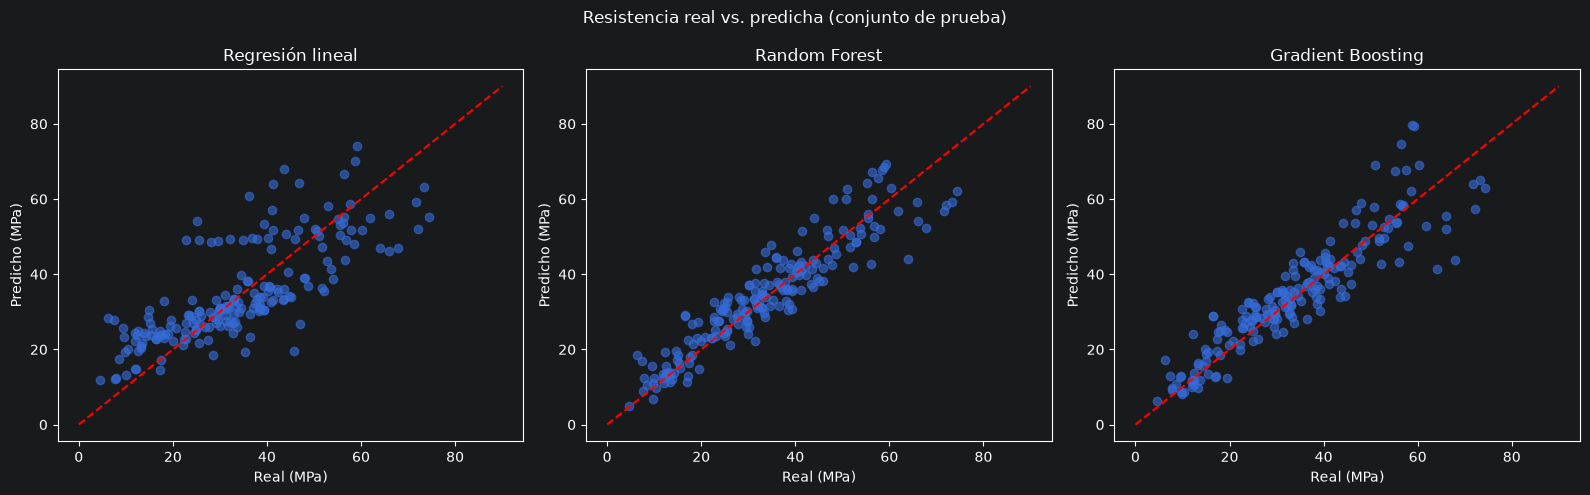

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nombre, modelo) in zip(axes, modelos.items()):
    pred = modelo.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.6)
    ax.plot([0, 90], [0, 90], "r--")
    ax.set_title(nombre)
    ax.set_xlabel("Real (MPa)")
    ax.set_ylabel("Predicho (MPa)")

fig.suptitle("Resistencia real vs. predicha (conjunto de prueba)")
plt.tight_layout()
plt.show()

### Resistencia real vs. predicha

Si el modelo fuera perfecto, todos los puntos estarían sobre la línea roja.

**Observaciones:**
- Random Forest y Gradient Boosting quedan más cerca de la línea.
- Los tres modelos subestiman las resistencias altas (más de 60 MPa), porque
  hay pocos ejemplos de ese tipo.
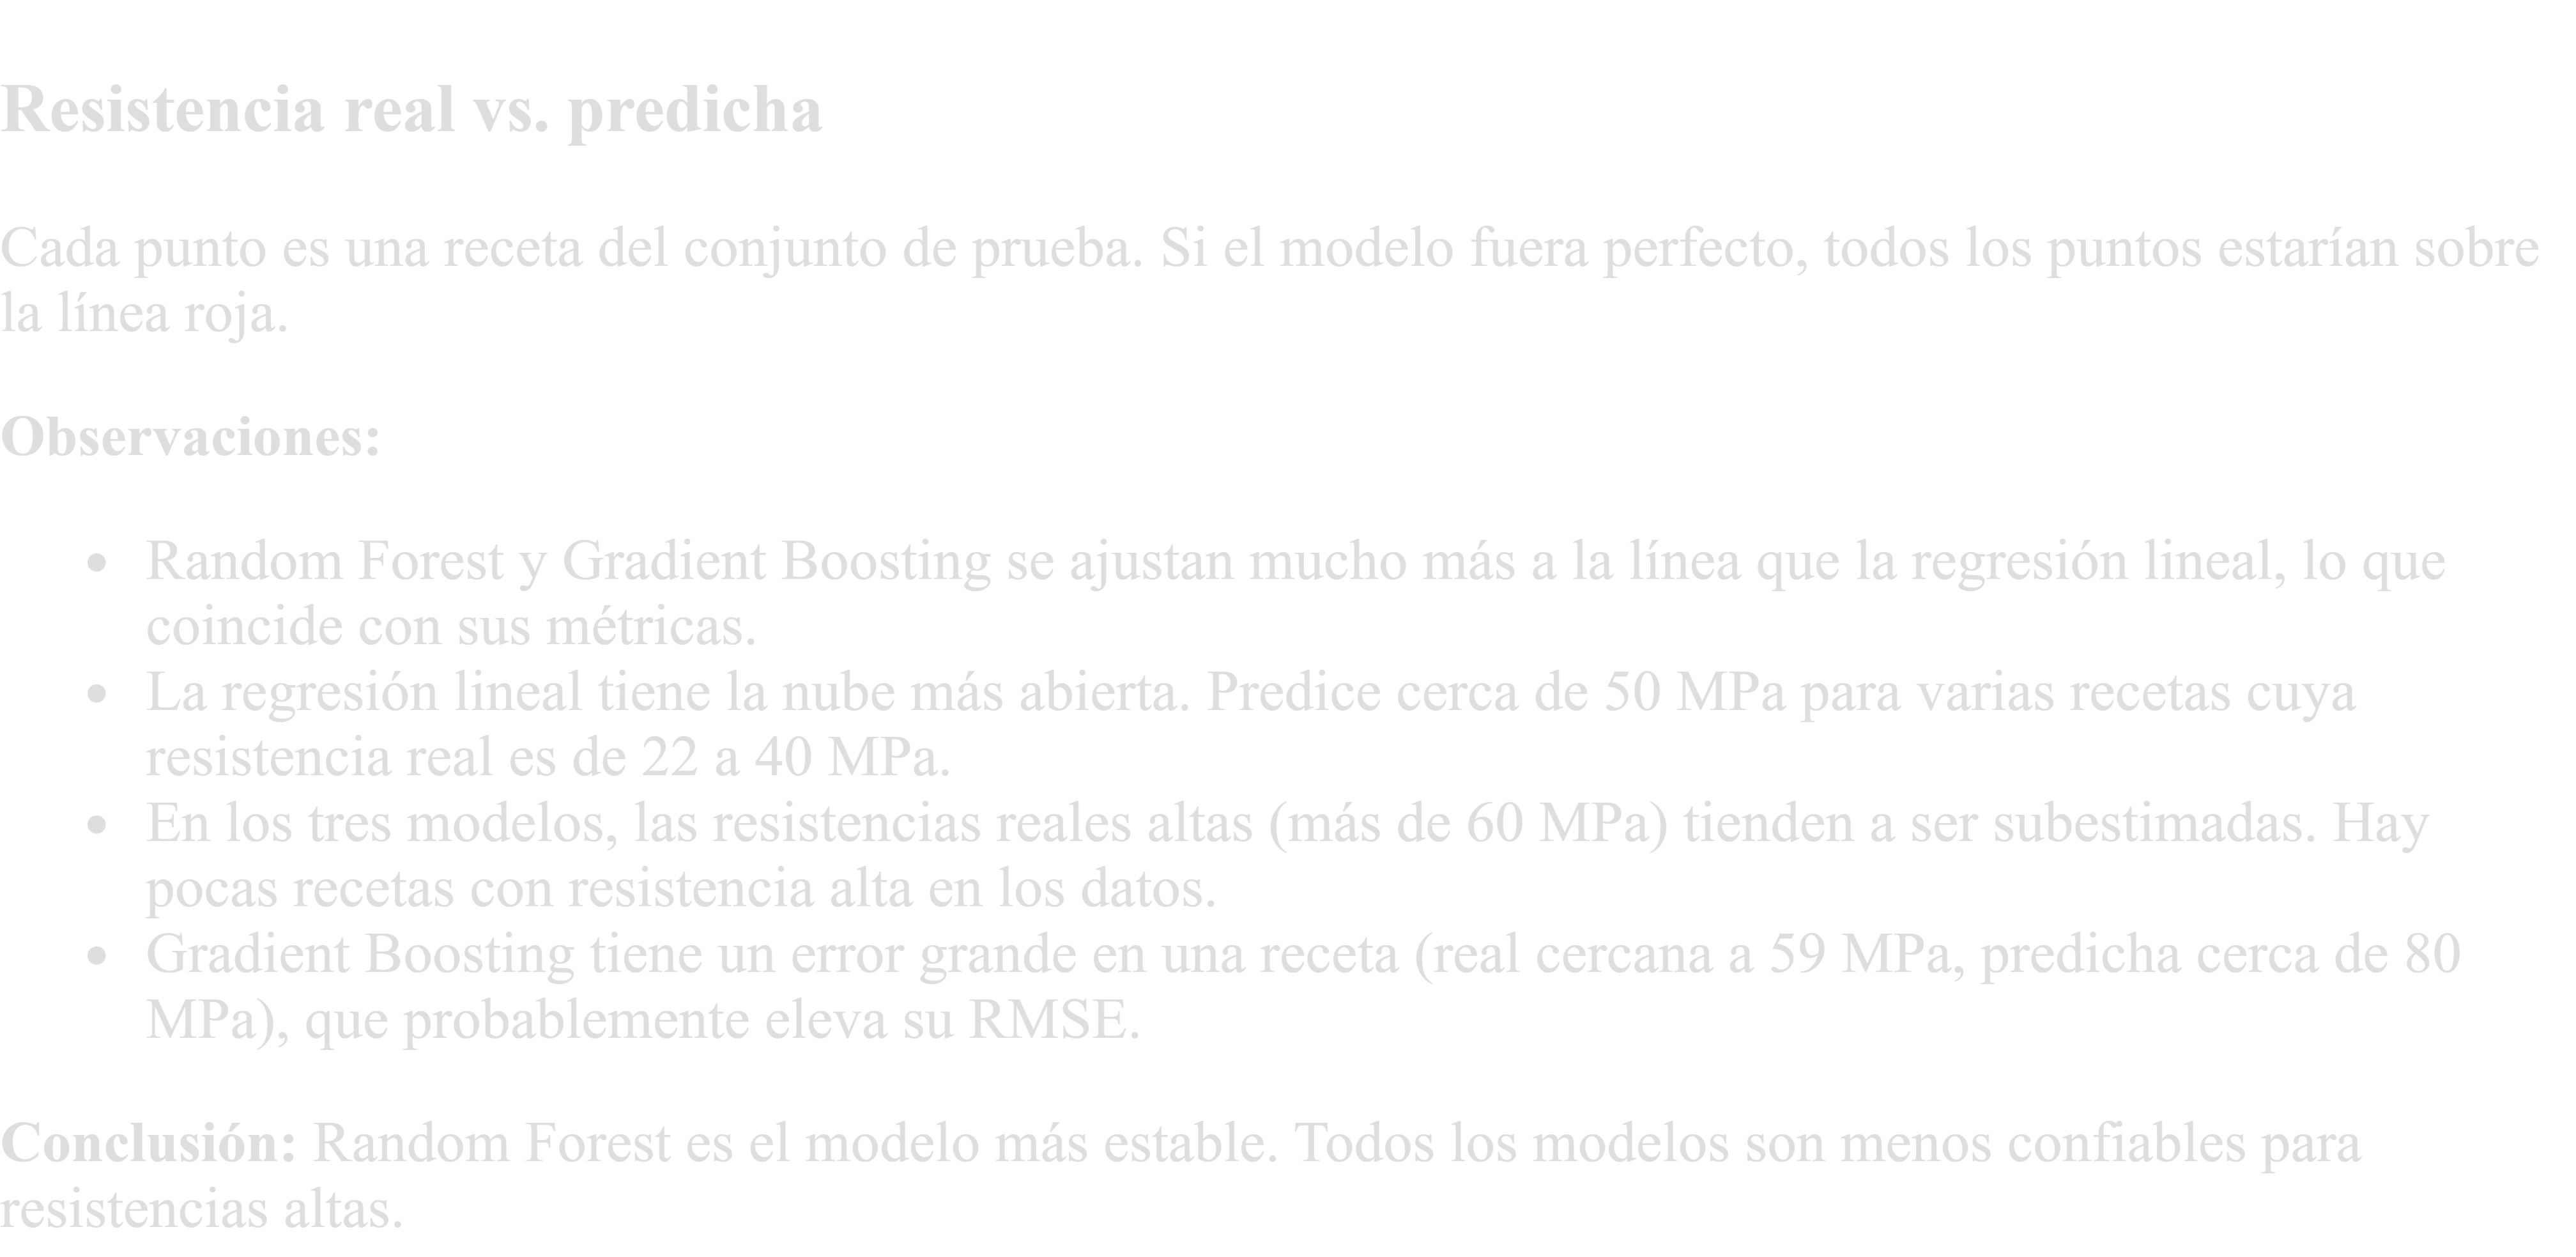
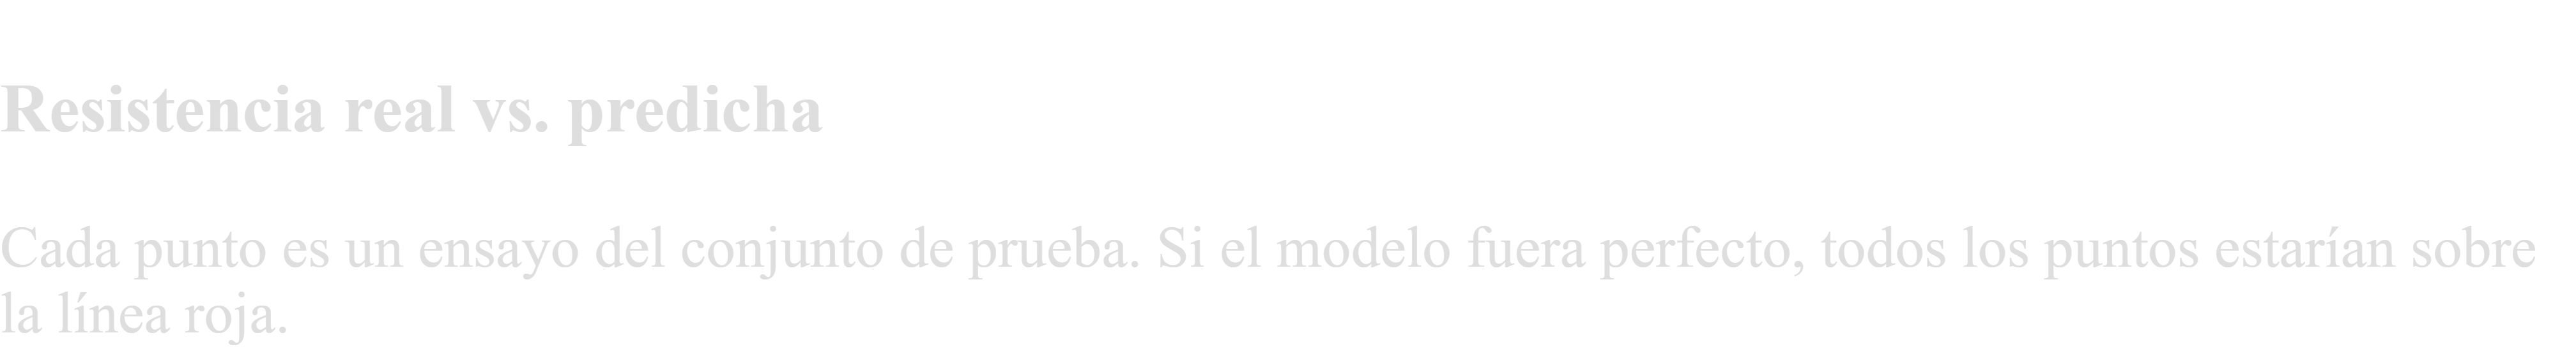

## 6. Importancia de variables

Qué variables usa más el modelo elegido (Random Forest) para predecir.

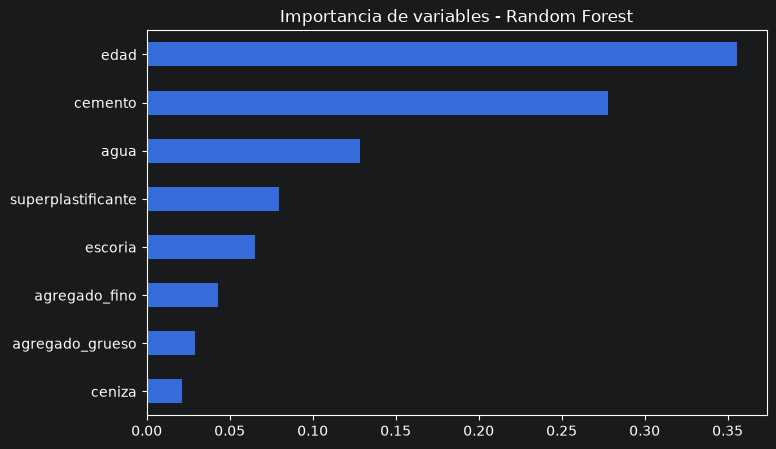

In [15]:
rf = modelos["Random Forest"]
importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

importancia.plot(kind="barh", figsize=(8, 5),
                 title="Importancia de variables - Random Forest")
plt.show()

### Importancia según Random Forest

Mide cuánto ayuda cada variable a reducir el error dentro de los árboles.

**Observaciones:**
- Edad y cemento son las más importantes (juntas, cerca del 63 %).
- Les sigue el agua. Agregados y ceniza aportan poco.
- La edad es la más importante aunque su correlación es baja: su relación
  con la resistencia es curva, y la correlación solo mide líneas rectas.
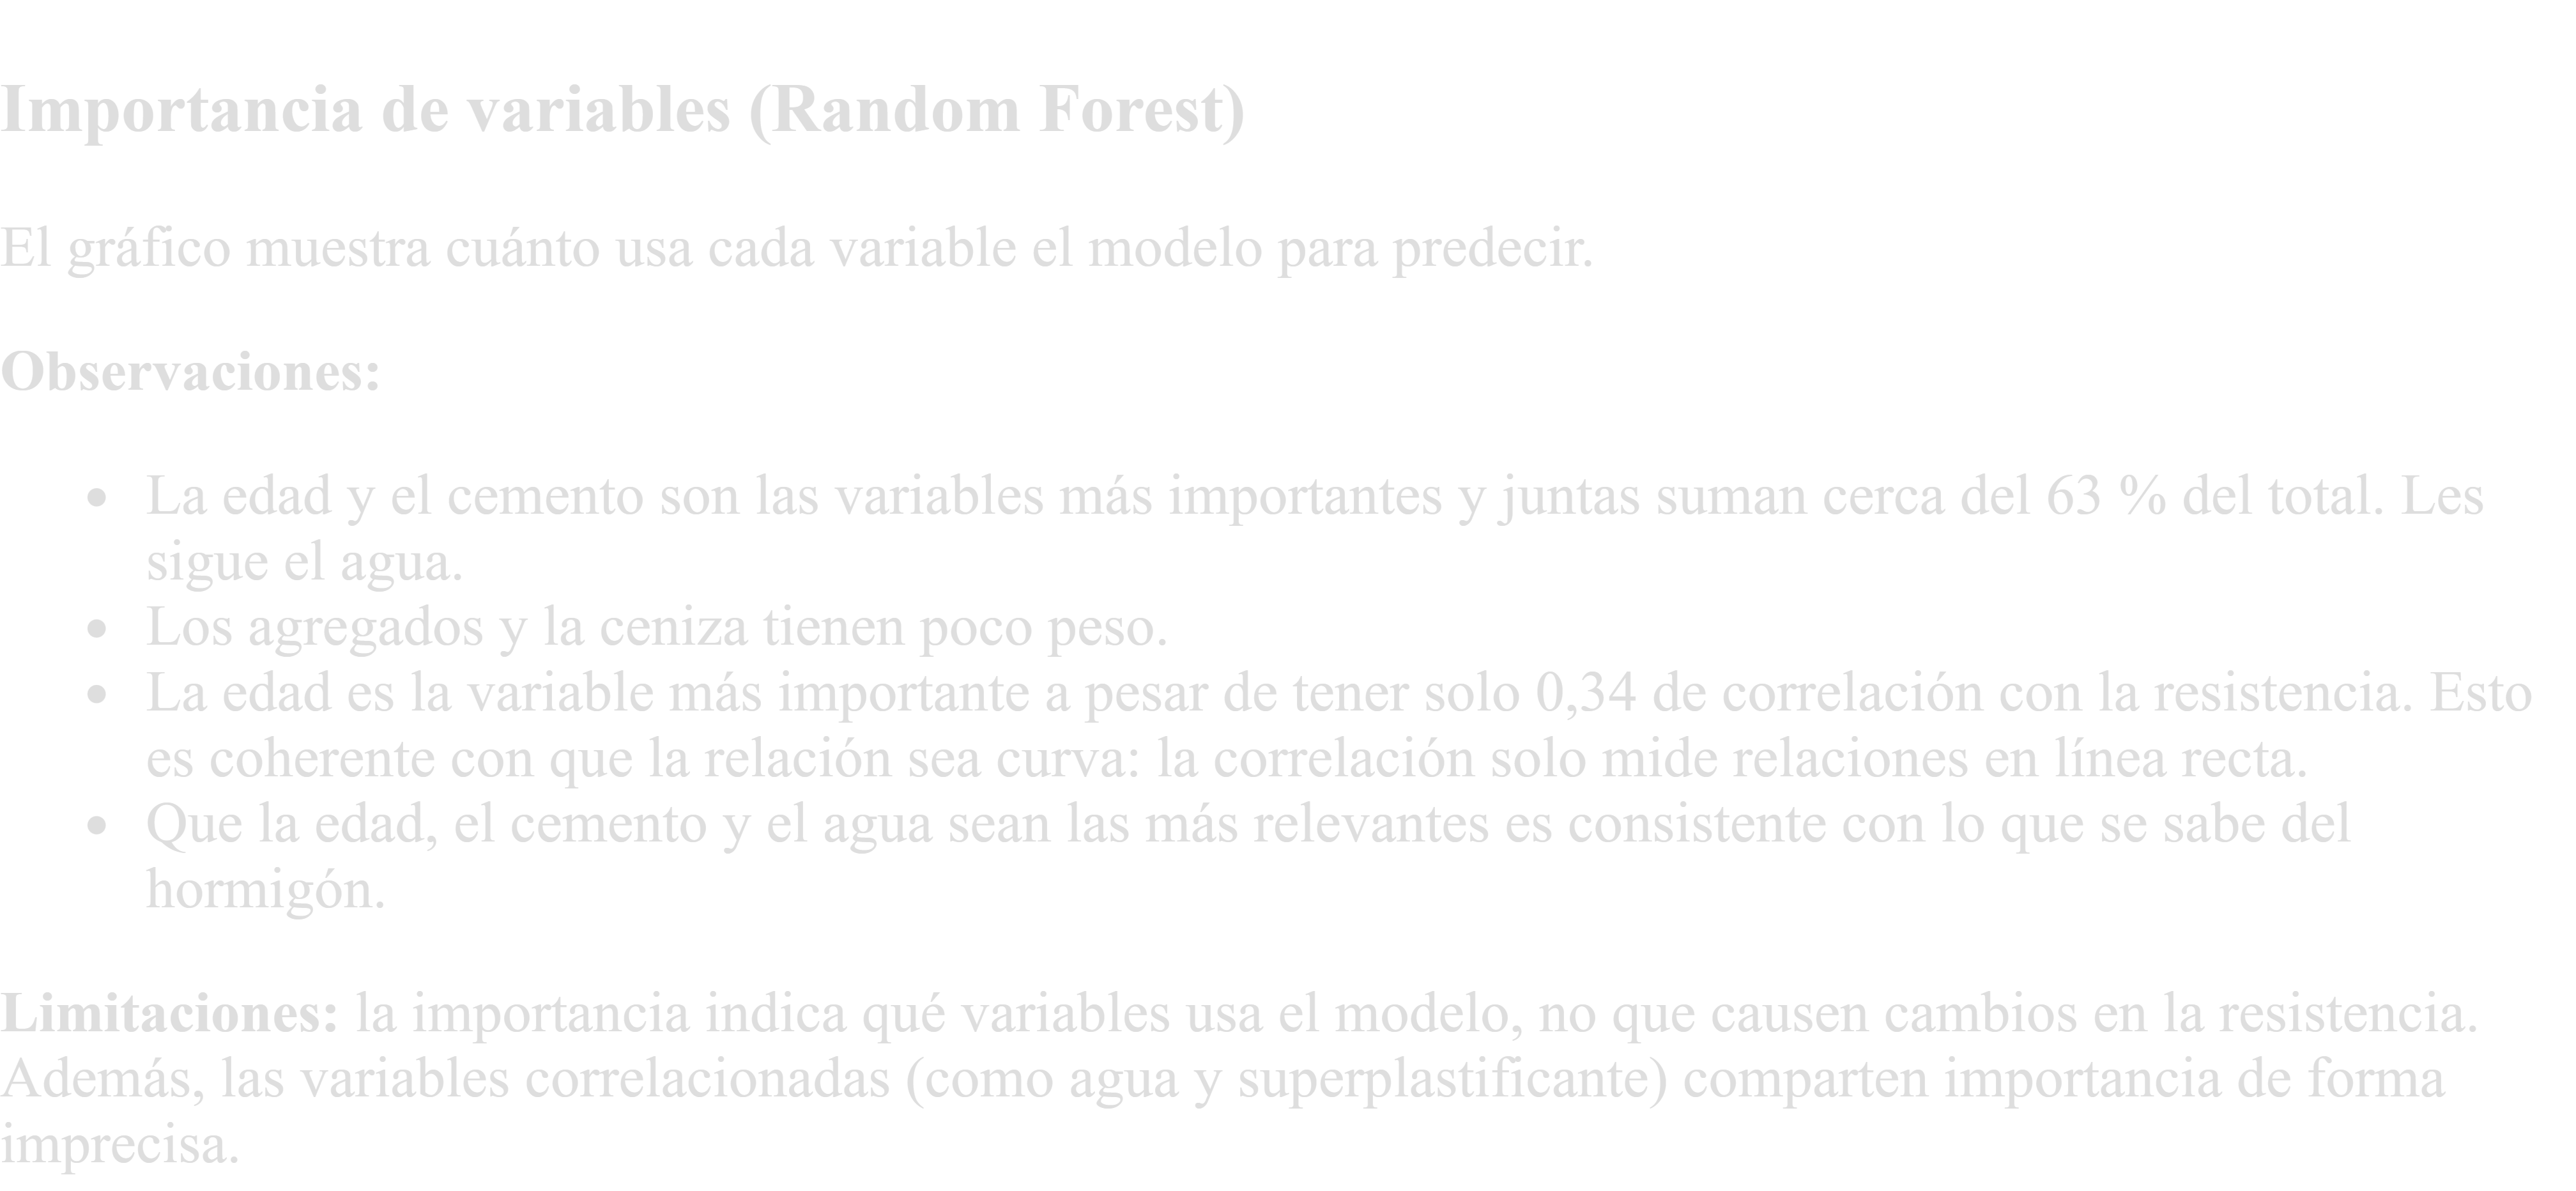

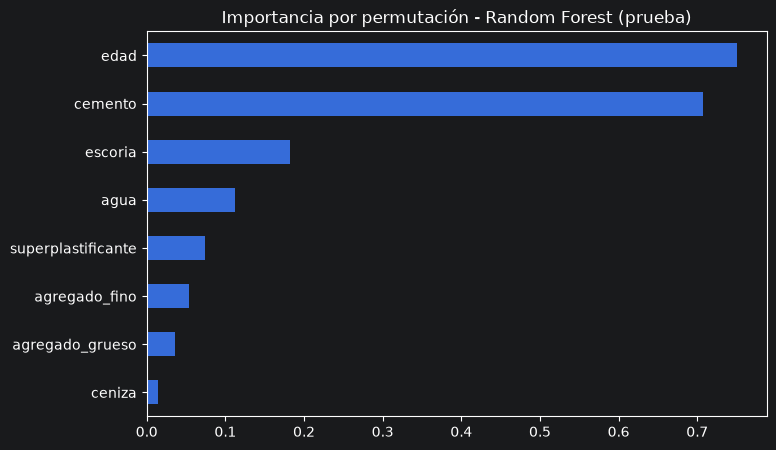

In [16]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)
imp_perm = pd.Series(perm.importances_mean, index=X.columns).sort_values()

imp_perm.plot(kind="barh", figsize=(8, 5),
              title="Importancia por permutación - Random Forest (prueba)")
plt.show()

### Importancia por permutación

Se desordena una variable a la vez y se mide cuánto empeora la predicción.
Si empeora mucho, la variable es importante.

**Observaciones:**
- Edad y cemento son las variables más importantes: coincide con
  la importancia de Random Forest.
- La escoria sube al tercer lugar, por delante del agua. En Random Forest el
  tercer lugar era el agua.
- Ceniza y agregados vuelven a ser las que menos aportan.
- Los dos métodos coinciden en lo principal: la resistencia depende sobre
  todo de la edad y del cemento.

## 7. Interpretación final

**Objetivo:** predecir la resistencia del hormigón a partir de la mezcla y la edad.

**Datos:** 1005 ensayos (sin duplicados) y 427 recetas distintas. Se dividió
por receta para evaluar con mezclas que el modelo no vio.

**Resultado:** Random Forest fue el mejor modelo. Explica el 85 % de la
variación y se equivoca en promedio 4,5 MPa. La regresión lineal quedó atrás
porque no capta relaciones curvas, como la de la edad.

**Variables clave:** edad y cemento, en los dos métodos. Les siguen la escoria
y el agua, cuyo orden cambia según el método. Coincide con lo que se sabe del
hormigón: gana resistencia con el tiempo y con el cemento, y la pierde con
más agua.

**Limitaciones:** el dataset es chico, hay pocos ensayos de edades largas y
de resistencias altas.